# 2026-10-15: NGC4654 normalized rSFMS excess, Fourier asymmetry and local SF enhancement

Follow the final combined workflow in [the linked discussion](https://chatgpt.com/c/6ac9e7e4-b9f0-83ec-ab29-b9ec84758f55):
pre-peak rSFMS and width -> direction-free close-to-peak comparison -> MUSE-only
Fourier localization of normalized SFR excess -> peak/opposite sector tails ->
full-footprint pre-peak context -> delayed VIVA comparison.

Both source notebooks are preserved. This is an exploratory selected case study:
NGC4654 and the historical NW result were already known. "Blind" here means
the numerical phase fit uses MUSE coordinates and observables without an H I
direction constraint. It is not a preregistered discovery or an independent
confirmation of the subsequently selected sector.

## Material Passport
Artifact: executable exploratory analysis; date: 2026-10-15; inputs: live local
MAUVE products and the two source notebooks; primary observable: normalized
rSFMS residual E. Implementation verification appears at the end. Claims depend
on the live run; historical numerical results are not imposed.

**2026-10-15 update:** copied from the 20261012 notebook; Fourier fits and
resampling refits use Levenberg-Marquardt. Excess-tail thresholds are
1, 1.5, 2, 2.5, 3, 3.5 and 4. Outputs are cleared pending a fresh run.

**2026-10-13 geometry revision:** harmonic fitting, angular-coverage gates and
peak/opposite sectors now use projected sky PA throughout. Elliptical R/Re
is retained solely for radial control. Earlier deprojected-angle outputs have
been cleared and are replaced by the current projected run.


In [1]:
from pathlib import Path
import hashlib, platform
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display, Markdown

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
GALAXY_COLOR_PATH = PROJECT_ROOT / 'MAUVE_galaxy_colors.dat'
I_MAX_EXCLUSIVE = 80.0
EW_HA_MIN = 6.0
HALPHA_SIGMA_MAX = 45.0
WCS_TOLERANCE_ARCSEC = 0.05
MASS_HDU = 'LOGMASS_SURFACE_DENSITY'
BIN_HDU_MASS = 'BINID'
BIN_HDU_GAS = 'BIN_ID'
SFR_HDU_PRIMARY = 'LOGSFR_SURFACE_DENSITY_HII'
EW_HDU = 'PROXY_EWHA'
HALPHA_SIGMA_OBS_HDU = 'HA6562_SIGMA'
HALPHA_SIGMA_CORR_HDU = 'HA6562_SIGMA_CORR'
MASK_TABLE_HDU = 'MASKFILE'
MASK_COLUMN = 'MASK'
MASS_FILE_PATTERN = '{galid}_spatial_binning_maps_further.fits'
SFR_FILE_PATTERNS = ('{galid}_gas_bin_maps_further.fits', '{galid}_gas_BIN_maps_further.fits')
EW_FILE_PATTERNS = ('{galid}_proxy_EW_maps_further.fits', '{galid}_proxy_EW_maps.fits')
MASK_FILE_PATTERN = '{galid}_mask.fits'
MAP_LIMIT = 4.0  # display saturation only; fractions/histograms use all values
mpl.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': False})
EXCESS_THRESHOLDS = (1, 1.5, 2, 2.5, 3, 3.5, 4)
TARGET = 'NGC4654'
SEED = 20261012
RADIAL_STEP = 0.4
N_ANGULAR_SECTORS = 12
MIN_ANGULAR_SECTORS = 9
MIN_PIXELS_ANNULUS = 30
MIN_BINS_ANNULUS = 20
MIN_BINS_FIT = 20
MAX_DESIGN_CONDITION = 1e6
N_BOOT = 499
N_NULL = 999
ALPHA = 0.05
SECTOR_HALF_WIDTH_DEG = 45.0

## 1. Live sample, masks and map provenance


Inherited SF selection: finite HII log SFR and stellar density, unmasked usable
footprint, proxy EW(Halpha)>6 Angstrom, and 0<intrinsic Halpha dispersion<45 km/s.
Intrinsic dispersion is sqrt(observed dispersion squared minus correction
squared). No additional SFR-error cut is imposed on fitting or excess maps.

The current products have no dedicated SFR-error HDU. Since SFR is proportional
to corrected Halpha flux, derive the first-order log SFR error in dex as
`HA6562_FLUX_ERR_CORR / (HA6562_FLUX_CORR * ln(10))`. Use the existing corrected
flux uncertainty, which includes the pipeline's dust-error treatment; do not
add that term again. Fixed conversion/area factors cancel in the relative error.
Distance, inclination, calibration systematics, stellar-density errors, and
fitted-line uncertainty are not included. Invalid/negative errors are excluded
only from width estimation and their counts are displayed.

In [2]:
def normalise_stage_label(value) -> str:
    mapping = {
        1: "pre-peak", 1.0: "pre-peak", "1": "pre-peak",
        2: "close-to-peak", 2.0: "close-to-peak", "2": "close-to-peak",
        3: "post-peak", 3.0: "post-peak", "3": "post-peak",
        "prepeak": "pre-peak", "pre-peak": "pre-peak",
        "close-to-peak": "close-to-peak", "closetopeak": "close-to-peak",
        "near-peak": "close-to-peak", "postpeak": "post-peak",
        "post-peak": "post-peak",
    }
    key = value if isinstance(value, (int, float)) else str(value).strip().lower().replace(" ", "")
    if key not in mapping:
        raise ValueError(f"Unrecognised RPS/infall stage label: {value!r}")
    return mapping[key]

def first_existing(paths):
    for path in paths:
        if path.exists():
            return path
    return None

def load_fits_map(path: Path, hdu_name: str, *, return_header: bool = False):
    if not path.exists():
        raise FileNotFoundError(path)
    with fits.open(path, memmap=True) as hdul:
        names = {h.name.upper() for h in hdul}
        if hdu_name.upper() not in names:
            raise KeyError(f"{path}: missing HDU {hdu_name}; available={sorted(names)}")
        hdu = hdul[hdu_name]
        data = np.asarray(hdu.data, dtype=float).copy()
        header = hdu.header.copy()
    return (data, header) if return_header else data

def load_ngist_mask(path: Path, shape):
    if not path.exists():
        raise FileNotFoundError(path)
    with fits.open(path, memmap=True) as hdul:
        if MASK_TABLE_HDU not in hdul:
            raise KeyError(f"{path}: missing table HDU {MASK_TABLE_HDU}")
        table = hdul[MASK_TABLE_HDU].data
        if MASK_COLUMN not in table.names:
            raise KeyError(f"{path}: missing mask column {MASK_COLUMN}; available={table.names}")
        flat = np.asarray(table[MASK_COLUMN], dtype=int)
    if flat.size != int(np.prod(shape)):
        raise ValueError(f"{path}: mask length {flat.size} cannot reshape to {shape}")
    return flat.reshape(shape)

def celestial_wcs_separation_arcsec(header_a, header_b, shape):
    wa = WCS(header_a).celestial
    wb = WCS(header_b).celestial
    if not wa.has_celestial or not wb.has_celestial:
        return np.inf
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    raa, deca = wa.pixel_to_world_values(x, y)
    rab, decb = wb.pixel_to_world_values(x, y)
    cosd = np.cos(np.deg2rad((deca + decb) / 2))
    return float(np.nanmax(np.hypot((raa - rab) * cosd, deca - decb)) * 3600.0)

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    """Return min elliptical R/Re over physical components (union geometry for NGC4567_8)."""
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, row in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(ra, dec, row.center_ra_deg, row.center_dec_deg)
        pa = np.deg2rad(float(row.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        r = np.sqrt((major / float(row.a_re_arcsec)) ** 2 + (minor / float(row.b_re_arcsec)) ** 2)
        radius = np.minimum(radius, r)
    radius[~np.isfinite(radius)] = np.nan
    return radius

def make_valid_disc_mask(log_sigma_star, bin_id, ngist_mask, radius_re):
    return (
        np.isfinite(log_sigma_star)
        & np.isfinite(bin_id)
        & (ngist_mask == 0)
        & np.isfinite(radius_re)
    )

def intrinsic_sigma_from_maps(sigma_obs, sigma_corr):
    sigma_obs = np.asarray(sigma_obs, dtype=float)
    sigma_corr = np.asarray(sigma_corr, dtype=float)
    if sigma_obs.shape != sigma_corr.shape:
        raise ValueError(
            f"Observed/correction Halpha sigma shape mismatch: {sigma_obs.shape} vs {sigma_corr.shape}"
        )
    sigma2_intrinsic = sigma_obs**2 - sigma_corr**2
    sigma_intrinsic = np.full(sigma_obs.shape, np.nan, dtype=float)
    valid = np.isfinite(sigma2_intrinsic) & (sigma2_intrinsic > 0)
    sigma_intrinsic[valid] = np.sqrt(sigma2_intrinsic[valid])
    return sigma_intrinsic

def make_sf_mask(valid_disc_mask, log_sigma_sfr, ew_ha, halpha_sigma_intrinsic):
    """Project SF definition: HII/SF map + EW(Halpha)>6 A + intrinsic sigma<45 km/s."""
    return (
        valid_disc_mask
        & np.isfinite(log_sigma_sfr)
        & np.isfinite(ew_ha)
        & (ew_ha > EW_HA_MIN)
        & np.isfinite(halpha_sigma_intrinsic)
        & (halpha_sigma_intrinsic < HALPHA_SIGMA_MAX)
    )

def load_galaxy_maps(row, geometry, sfr_hdu=SFR_HDU_PRIMARY):
    mass, mass_header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    mass_bin = load_fits_map(row.mass_path, BIN_HDU_MASS)
    gas_bin, gas_header = load_fits_map(row.sfr_path, BIN_HDU_GAS, return_header=True)
    sfr = load_fits_map(row.sfr_path, sfr_hdu)
    ew_ha = load_fits_map(row.ew_path, EW_HDU)
    halpha_sigma_obs = load_fits_map(row.sfr_path, HALPHA_SIGMA_OBS_HDU)
    halpha_sigma_corr = load_fits_map(row.sfr_path, HALPHA_SIGMA_CORR_HDU)
    shapes = {
        mass.shape, mass_bin.shape, gas_bin.shape, sfr.shape, ew_ha.shape,
        halpha_sigma_obs.shape, halpha_sigma_corr.shape,
    }
    if len(shapes) != 1:
        raise ValueError(f"{row.GALID}: map shape mismatch {sorted(shapes)}")
    wcs_sep = celestial_wcs_separation_arcsec(mass_header, gas_header, mass.shape)
    if not np.isfinite(wcs_sep) or wcs_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f"{row.GALID}: mass/gas WCS mismatch {wcs_sep:.4f} arcsec")
    ngist_mask = load_ngist_mask(row.mask_path, mass.shape)
    components = geometry.loc[geometry.notebook_product_id.eq(row.GALID)].copy()
    if components.empty:
        raise KeyError(f"{row.GALID}: no geometry rows")
    radius_re = calculate_deprojected_radius(mass.shape, mass_header, components)
    halpha_sigma_intrinsic = intrinsic_sigma_from_maps(halpha_sigma_obs, halpha_sigma_corr)
    valid = make_valid_disc_mask(mass, gas_bin, ngist_mask, radius_re)
    classification = valid & np.isfinite(sfr)
    sf = make_sf_mask(valid, sfr, ew_ha, halpha_sigma_intrinsic)
    return {
        "log_sigma_star": mass,
        "log_sigma_sfr": sfr,
        "ew_ha": ew_ha,
        "halpha_sigma_intrinsic": halpha_sigma_intrinsic,
        "mass_bin_id": mass_bin,
        "gas_bin_id": gas_bin,
        "ngist_mask": ngist_mask,
        "radius_re": radius_re,
        "valid_disc_mask": valid,
        "classification_mask": classification,
        "sf_mask": sf,
        "wcs_separation_arcsec": wcs_sep,
    }

def load_galaxy_colors(path):
    """Read the fixed, project-approved MAUVE galaxy colour mapping."""
    colors = {}
    for line in path.read_text().splitlines():
        fields = line.split()
        if not fields or fields[0].startswith("#") or fields[0] == "reserved":
            continue
        if fields[0] == "alias":
            colors[fields[1]] = fields[3]
        elif fields[0].isdigit():
            colors[fields[1]] = fields[3]
    return colors

def read_master_catalogue(path):
    with fits.open(path) as hdul:
        table = hdul[1].data
        required = {"Galaxy", "logMstar", "class"}
        missing = required - set(table.names)
        if missing:
            raise KeyError(f"{path}: missing catalogue columns {sorted(missing)}")
        frame = pd.DataFrame({
            "galaxy": [str(v).strip() for v in table["Galaxy"]],
            "logMstar": np.asarray(table["logMstar"], dtype=float),
            "stage_code": np.asarray(table["class"], dtype=float),
        })
    frame["stage"] = frame.stage_code.map(normalise_stage_label)
    return frame

def discover_products(data_root):
    rows = []
    for folder in sorted(p for p in data_root.iterdir() if p.is_dir() and not p.name.endswith("_logs")):
        galid = folder.name
        mass_base = folder / MASS_FILE_PATTERN.format(galid=galid)
        mass = first_existing([mass_base, Path(str(mass_base)+'.gz')]) or mass_base
        sfr_paths = [folder / p.format(galid=galid) for p in SFR_FILE_PATTERNS]
        sfr = first_existing(sfr_paths + [Path(str(p)+'.gz') for p in sfr_paths])
        ew_paths = [folder / p.format(galid=galid) for p in EW_FILE_PATTERNS]
        ew = first_existing(ew_paths + [Path(str(p)+'.gz') for p in ew_paths])
        mask_base = folder / MASK_FILE_PATTERN.format(galid=galid)
        mask = first_existing([mask_base, Path(str(mask_base)+'.gz')]) or mask_base
        rows.append({"GALID": galid, "mass_path": mass, "sfr_path": sfr, "ew_path": ew, "mask_path": mask})
    return pd.DataFrame(rows)

def projected_sky_angle(east,north):
    """Sky PA in radians: north=0, east=pi/2; origin has undefined angle."""
    east,north=np.asarray(east,dtype=float),np.asarray(north,dtype=float)
    return np.where(np.hypot(east,north)>0,np.arctan2(east,north)%(2*np.pi),np.nan)


In [3]:
SOURCE_SHA256_AT_CREATION = {'20261012_check_blind_pre_peak_rSFMS_SF_excess_all_galaxies.ipynb': '4506c913856a05753288a37af8c7e127090784f50345fd18aebab1b608db516e', '20261010_check_NGC4654_blind_SF_asymmetry_enhancement.ipynb': '7bfe860f9ab0ecdbaf2024fdcbbfdbe9590c88d9a5ecf4d4a495550655d40960'}
print('Source notebook hashes:', SOURCE_SHA256_AT_CREATION)
for p in (CATALOG_PATH, GEOMETRY_PATH, GALAXY_COLOR_PATH):
    print(p.name, hashlib.sha256(p.read_bytes()).hexdigest())
master = read_master_catalogue(CATALOG_PATH)
geometry = pd.read_csv(GEOMETRY_PATH).merge(master[['galaxy', 'logMstar', 'stage']],
    on='galaxy', how='left', validate='one_to_one')
assert geometry.stage.notna().all()
assert geometry.stage.eq(geometry.mauve_infall_stage.map(normalise_stage_label)).all()
meta = []
for galid, group in geometry.groupby('notebook_product_id', sort=True):
    if group.stage.nunique() != 1:
        raise ValueError(f'{galid}: mixed stages within combined product')
    meta.append(dict(GALID=galid, stage=group.stage.iloc[0],
        n_components=len(group), inclination=group.inclination_deg.max()))
inventory = pd.DataFrame(meta).merge(discover_products(DATA_ROOT), on='GALID',
    how='outer', validate='one_to_one')
inventory['included'] = (inventory.stage.isin(['pre-peak', 'close-to-peak'])
    & inventory.inclination.lt(I_MAX_EXCLUSIVE))
inventory['selection_reason'] = np.where(inventory.included, 'selected',
    np.where(~inventory.stage.isin(['pre-peak','close-to-peak']),
             'outside requested stages / missing metadata', 'inclination >=80 / missing'))
display(inventory[['GALID','stage','n_components','inclination','selection_reason']])
selected = inventory.loc[inventory.included].copy()
pre_ids = sorted(selected.loc[selected.stage.eq('pre-peak'), 'GALID'])
close_ids = sorted(selected.loc[selected.stage.eq('close-to-peak'), 'GALID'])
print('Pre-peak:', len(pre_ids), pre_ids)
print('Close-to-peak:', len(close_ids), close_ids)
assert pre_ids and close_ids, 'Need both reference and comparison products'
assert TARGET in close_ids
galaxy_colors = load_galaxy_colors(GALAXY_COLOR_PATH)
assert all(g in galaxy_colors for g in pre_ids + close_ids)

Source notebook hashes: {'20261012_check_blind_pre_peak_rSFMS_SF_excess_all_galaxies.ipynb': '4506c913856a05753288a37af8c7e127090784f50345fd18aebab1b608db516e', '20261010_check_NGC4654_blind_SF_asymmetry_enhancement.ipynb': '7bfe860f9ab0ecdbaf2024fdcbbfdbe9590c88d9a5ecf4d4a495550655d40960'}
mauve_master_wiki_newclass.fits 05fbc2ba45b6cde2b02e67b6a06f646491b642c009186f0cd5176b9dc6e5af0c
MAUVE_effective_radii.csv e7f0300c43376fbc0d35977b4512a57b84169b8472b3febaba7bf67851d60111
MAUVE_galaxy_colors.dat 18874f26dacd3b5e8113574d7ba1d90a57cac19a6f4efa22673e76dc649dbab4


,GALID,stage,n_components,inclination,selection_reason
0,IC3392,post-peak,1,68,outside requested stages / missing metadata
1,NGC4064,post-peak,1,70,outside requested stages / missing metadata
2,NGC4189,pre-peak,1,42,selected
3,NGC4192,pre-peak,1,83,inclination >=80 / missing
4,NGC4216,post-peak,1,90,outside requested stages / missing metadata
5,NGC4222,pre-peak,1,90,inclination >=80 / missing
6,NGC4254,pre-peak,1,39,selected
7,NGC4293,post-peak,1,67,outside requested stages / missing metadata
8,NGC4294,pre-peak,1,74,selected
9,NGC4298,close-to-peak,1,52,selected


Pre-peak: 8 ['NGC4189', 'NGC4254', 'NGC4294', 'NGC4321', 'NGC4351', 'NGC4383', 'NGC4535', 'NGC4567_8']
Close-to-peak: 5 ['NGC4298', 'NGC4424', 'NGC4501', 'NGC4654', 'NGC4694']


In [4]:
samples, galaxy_maps, qc_rows = {}, {}, []
for row in selected.itertuples(index=False):
    for label in ('mass', 'sfr', 'ew', 'mask'):
        p = getattr(row, label + '_path')
        if not isinstance(p, Path) or not p.exists():
            raise FileNotFoundError(f'{row.GALID}: missing {label}: {p}')
    maps = load_galaxy_maps(row, geometry)
    _, header = load_fits_map(row.mass_path, MASS_HDU, return_header=True)
    _, ew_header = load_fits_map(row.ew_path, EW_HDU, return_header=True)
    ew_sep = celestial_wcs_separation_arcsec(header, ew_header, maps['sf_mask'].shape)
    if not np.isfinite(ew_sep) or ew_sep > WCS_TOLERANCE_ARCSEC:
        raise ValueError(f'{row.GALID}: EW WCS mismatch: {ew_sep} arcsec')
    flux = load_fits_map(row.sfr_path, 'HA6562_FLUX_CORR')
    flux_err = load_fits_map(row.sfr_path, 'HA6562_FLUX_ERR_CORR')
    assert flux.shape == flux_err.shape == maps['sf_mask'].shape
    error_ok = np.isfinite(flux) & (flux > 0) & np.isfinite(flux_err) & (flux_err >= 0)
    err = np.full(flux.shape, np.nan)
    err[error_ok] = flux_err[error_ok] / flux[error_ok] / np.log(10.0)
    sf = maps['sf_mask']
    if not sf.any(): raise ValueError(f'{row.GALID}: no selected SF spaxels')
    # Check proportionality of stored log SFR to corrected Halpha on selected SF.
    delta_conversion = maps['log_sigma_sfr'][sf] - np.log10(flux[sf])
    assert np.isfinite(delta_conversion).all()
    conversion_range = np.ptp(delta_conversion)
    assert conversion_range < 1e-5, f'{row.GALID}: SFR/flux proportionality changed'
    yy, xx = np.indices(sf.shape)
    samples[row.GALID] = pd.DataFrame(dict(GALID=row.GALID, stage=row.stage,
        x=maps['log_sigma_star'][sf], y=maps['log_sigma_sfr'][sf],
        sfr_err_dex=err[sf], pixel_x=xx[sf], pixel_y=yy[sf]))
    maps['header'] = header
    galaxy_maps[row.GALID] = maps
    qc_rows.append(dict(GALID=row.GALID, stage=row.stage, N_SF=int(sf.sum()),
        N_valid_error=int(np.isfinite(err[sf]).sum()),
        N_invalid_error=int((~np.isfinite(err[sf])).sum()),
        mass_gas_WCS_arcsec=maps['wcs_separation_arcsec'], EW_WCS_arcsec=ew_sep,
        SFR_flux_log_conversion_range=conversion_range))
    print(row.GALID, 'loaded:', int(sf.sum()), 'SF spaxels')
qc = pd.DataFrame(qc_rows)
display(qc)

NGC4189 loaded: 96364 SF spaxels
NGC4254 loaded: 661963 SF spaxels
NGC4294 loaded: 68833 SF spaxels
NGC4298 loaded: 144157 SF spaxels
NGC4321 loaded: 454131 SF spaxels
NGC4351 loaded: 30711 SF spaxels
NGC4383 loaded: 25212 SF spaxels
NGC4424 loaded: 8994 SF spaxels
NGC4501 loaded: 251936 SF spaxels
NGC4535 loaded: 187113 SF spaxels
NGC4567_8 loaded: 222533 SF spaxels
NGC4654 loaded: 345036 SF spaxels
NGC4694 loaded: 1058 SF spaxels


,GALID,stage,N_SF,N_valid_error,N_invalid_error,mass_gas_WCS_arcsec,EW_WCS_arcsec,SFR_flux_log_conversion_range
0,NGC4189,pre-peak,96364,96364,0,0.0,0.0,8.881784e-16
1,NGC4254,pre-peak,661963,661963,0,0.0,0.0,1.776357e-15
2,NGC4294,pre-peak,68833,68833,0,0.0,0.0,1.776357e-15
3,NGC4298,close-to-peak,144157,144157,0,0.0,0.0,8.881784e-16
4,NGC4321,pre-peak,454131,454131,0,0.0,0.0,8.881784e-16
5,NGC4351,pre-peak,30711,30711,0,0.0,0.0,8.881784e-16
6,NGC4383,pre-peak,25212,25212,0,0.0,0.0,8.881784e-16
7,NGC4424,close-to-peak,8994,8994,0,0.0,0.0,1.776357e-15
8,NGC4501,close-to-peak,251936,251936,0,0.0,0.0,8.881784e-16
9,NGC4535,pre-peak,187113,187113,0,0.0,0.0,8.881784e-16


## 1.1. Equal-galaxy fit and requested intrinsic-width recipe

Let x=log10 stellar surface density [Msun/kpc2], y=log10 SFR surface density
[Msun/yr/kpc2], and f(x)=a x+b. Fit by minimizing
sum_g (1/N_g) sum_i [y_gi-f(x_gi)]^2 over pre-peak galaxies only. No inverse-error
weighting or mass-range cut is applied. Residuals are vertical offsets in dex.

For each pre-peak SF spaxel with a valid error, compute

$$q_{gi}=\sqrt{\max\{[y_{gi}-f(x_{gi})]^2-\sigma_{y,gi}^2,0\}},\qquad
W=\frac1G\sum_g\frac1{N_{g,\mathrm{err}}}\sum_i q_{gi}.$$

This implements quadrature subtraction **per absolute offset, before averaging**.
Negative radicands contribute zero, not missing values; their fraction is
reported. Each galaxy has equal width weight even if its valid-error count
differs. W is the requested corrected mean absolute width, not an unbiased
intrinsic standard deviation. In particular sqrt(mean(residual^2-error^2)) is
a different statistic and is not substituted here.

In [5]:
pre = pd.concat([samples[g] for g in pre_ids], ignore_index=True)
counts = pre.groupby('GALID').GALID.transform('size').to_numpy()
weights = 1.0 / counts
x, y = pre.x.to_numpy(), pre.y.to_numpy()
x_center = np.average(x, weights=weights)
y_center = np.average(y, weights=weights)
denom = np.sum(weights * (x-x_center)**2)
assert denom > 0
slope = np.sum(weights * (x-x_center) * (y-y_center)) / denom
intercept = y_center - slope*x_center
pre['fit_weight'] = weights
np.testing.assert_allclose(pre.groupby('GALID').fit_weight.sum(), 1.0)
def rsfms(x): return slope*np.asarray(x) + intercept
pre['residual_dex'] = pre.y - rsfms(pre.x)
width_sample = pre.loc[np.isfinite(pre.sfr_err_dex) & pre.sfr_err_dex.ge(0)].copy()
assert set(width_sample.GALID) == set(pre_ids), 'Every reference galaxy needs valid errors'
width_sample['radicand'] = width_sample.residual_dex**2 - width_sample.sfr_err_dex**2
width_sample['corrected_abs_dex'] = np.sqrt(np.maximum(width_sample.radicand, 0.0))
width_by_galaxy = width_sample.groupby('GALID').agg(
    N_width=('corrected_abs_dex','size'), width_g_dex=('corrected_abs_dex','mean'),
    mean_abs_offset_dex=('residual_dex', lambda v: np.mean(np.abs(v))),
    mean_SFR_err_dex=('sfr_err_dex','mean'),
    fraction_clipped_to_zero=('radicand',lambda v: np.mean(v <= 0)))
width_dex = float(width_by_galaxy.width_g_dex.mean())
assert np.isfinite(width_dex) and width_dex > 0
display(width_by_galaxy)
print(f'Pre-peak rSFMS: log Sigma_SFR = {slope:.6f} log Sigma_star {intercept:+.6f}')
print(f'Requested intrinsic absolute width W = {width_dex:.6f} dex')
display(Markdown(f'**Pre-peak reference:** y = {slope:.4f} x {intercept:+.4f}; '
    f'**requested width W = {width_dex:.4f} dex**, from {len(pre_ids)} equal-weight products.'))

,N_width,width_g_dex,mean_abs_offset_dex,mean_SFR_err_dex,fraction_clipped_to_zero
GALID,,,,,
NGC4189,96364,0.326038,0.327801,0.020660,0.030364
NGC4254,661963,0.423458,0.424630,0.014498,0.026050
NGC4294,68833,0.303254,0.303878,0.010362,0.019133
NGC4321,454131,0.359966,0.361936,0.022674,0.032154
NGC4351,30711,0.336563,0.337573,0.018610,0.025040
NGC4383,25212,0.275312,0.275952,0.010178,0.011978
NGC4535,187113,0.440557,0.441522,0.020060,0.014825
NGC4567_8,222533,0.318869,0.321515,0.025772,0.048209


Pre-peak rSFMS: log Sigma_SFR = 0.959663 log Sigma_star -9.688218
Requested intrinsic absolute width W = 0.348002 dex


**Pre-peak reference:** y = 0.9597 x -9.6882; **requested width W = 0.3480 dex**, from 8 equal-weight products.

/opt/miniconda3/envs/ICRAR/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


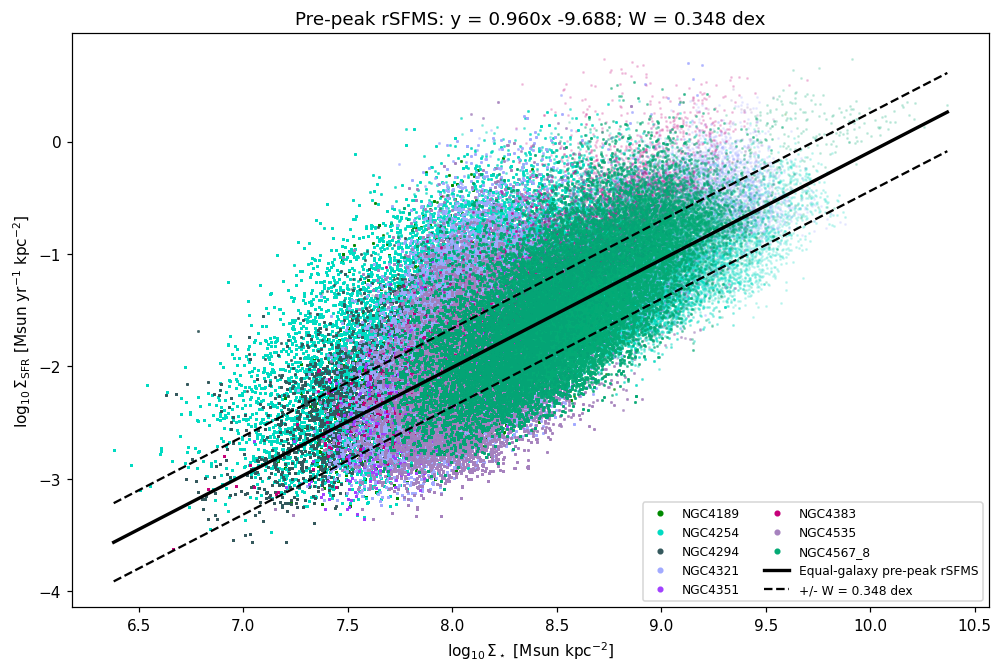

In [6]:
fig, ax = plt.subplots(figsize=(9,6), layout='constrained')
for g in pre_ids:
    f = samples[g]
    ax.scatter(f.x, f.y, color=galaxy_colors[g], s=1, alpha=.16, rasterized=True)
    # Opaque legend handles, independent of scatter transparency.
    ax.plot([], [], '.', color=galaxy_colors[g], label=g)
line_x = np.linspace(pre.x.min(), pre.x.max(), 300)
ax.plot(line_x, rsfms(line_x), color='black', lw=2.2, label='Equal-galaxy pre-peak rSFMS')
ax.plot(line_x, rsfms(line_x)+width_dex, color='black', ls='--', lw=1.5,
    label=f'+/- W = {width_dex:.3f} dex')
ax.plot(line_x, rsfms(line_x)-width_dex, color='black', ls='--', lw=1.5)
ax.set(xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
    ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
    title=f'Pre-peak rSFMS: y = {slope:.3f}x {intercept:+.3f}; W = {width_dex:.3f} dex')
ax.legend(fontsize=8, ncol=2)
plt.show()

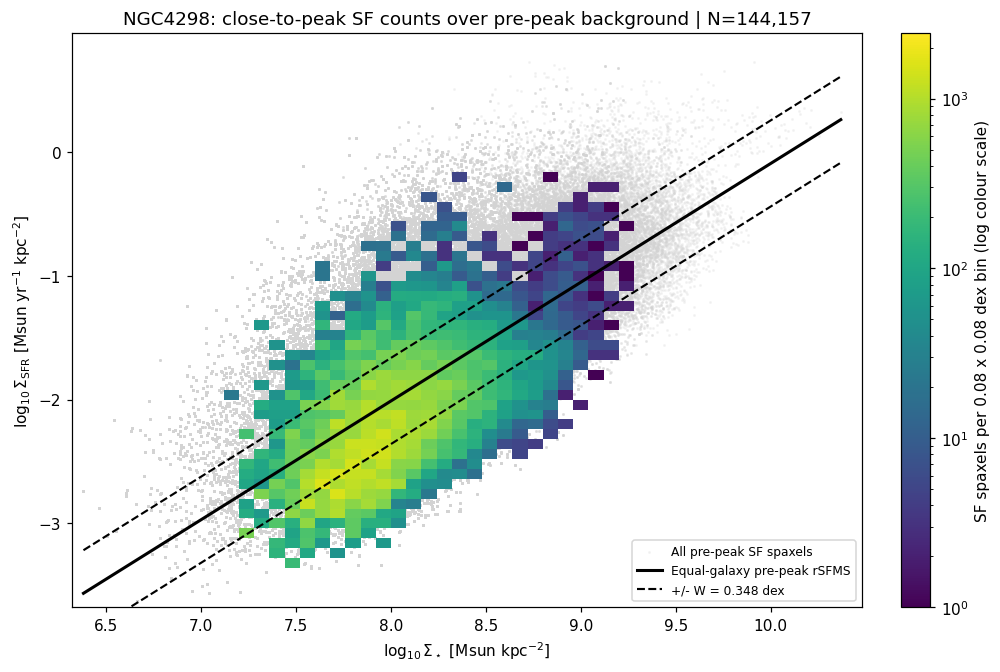

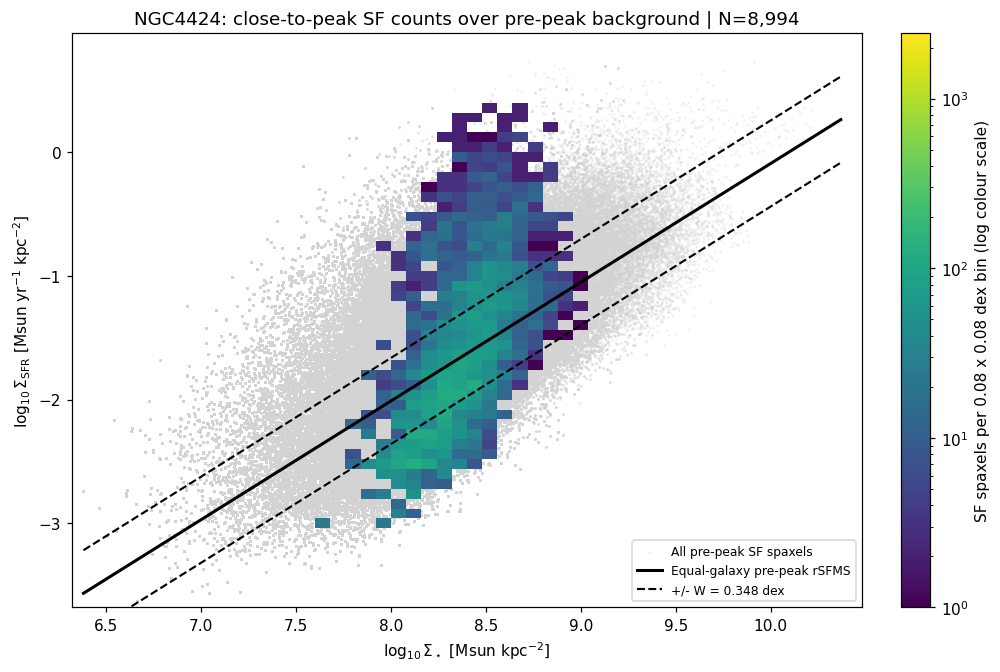

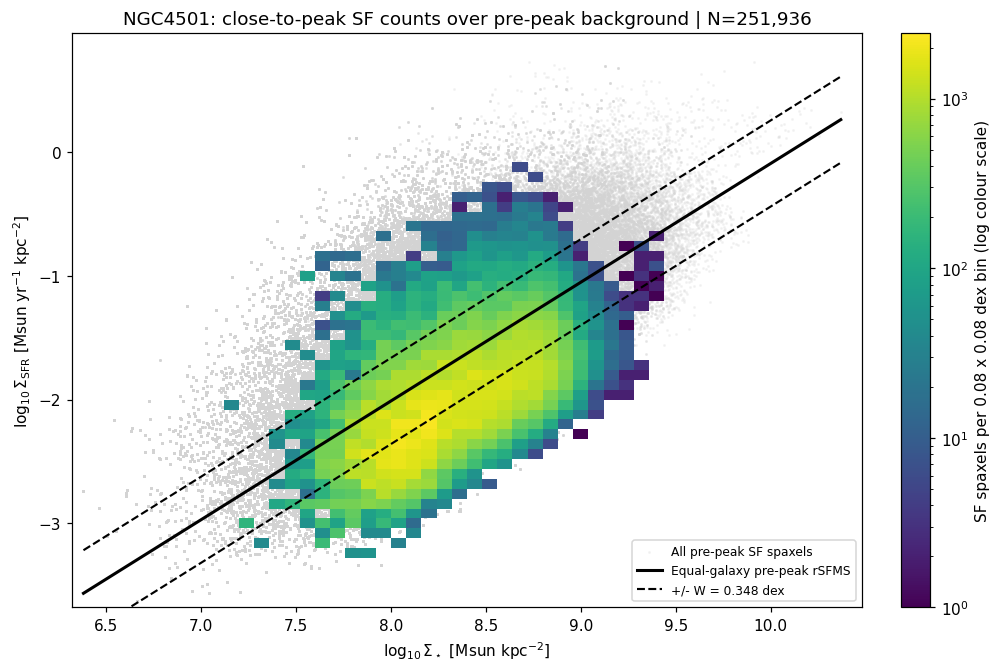

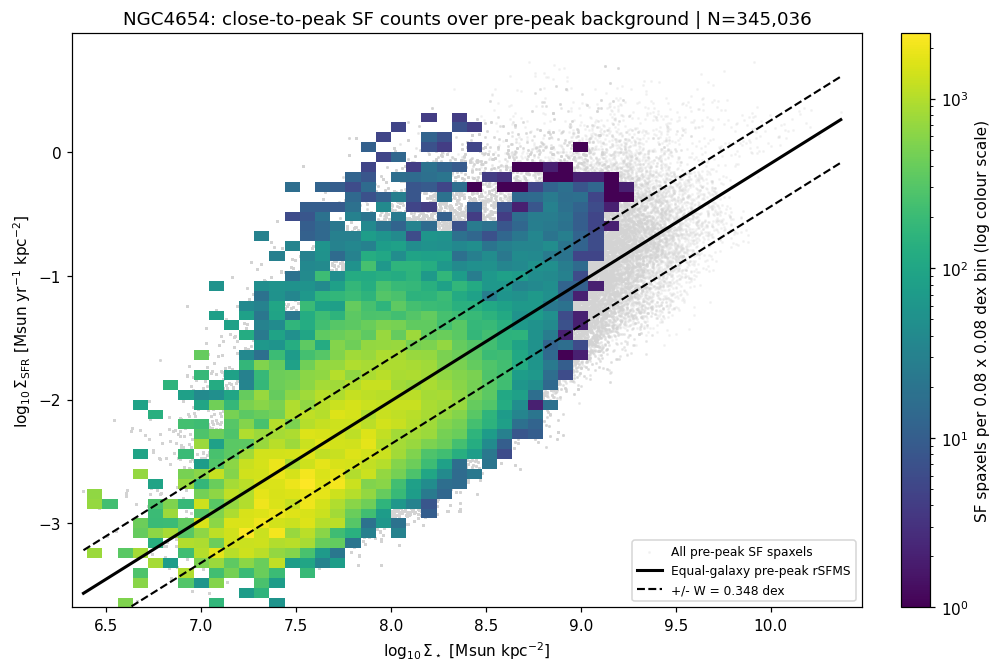

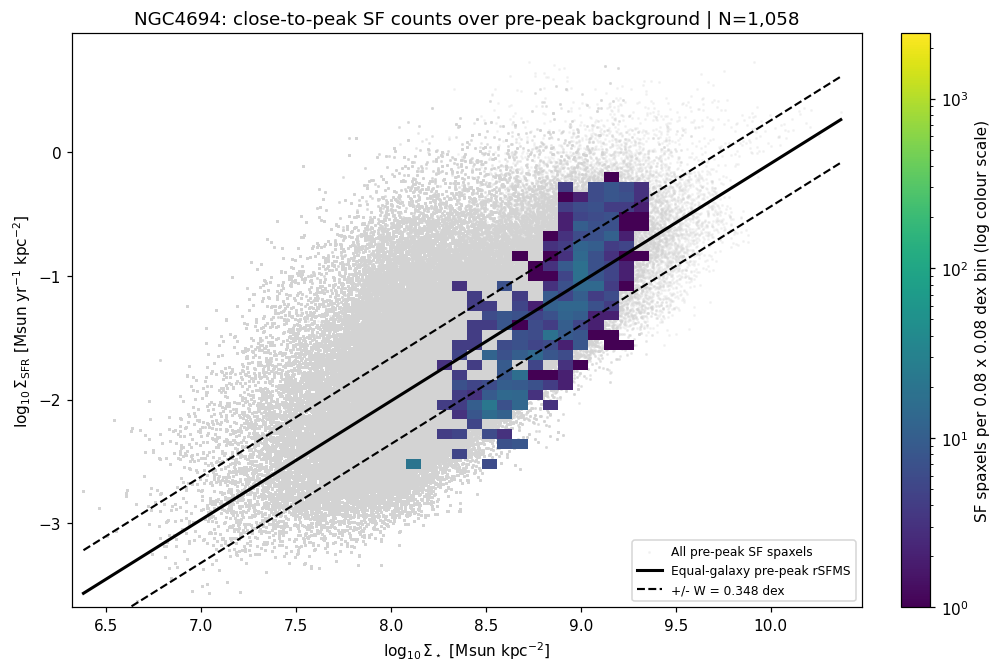

OVERLAY_CHECKS_OK: 5 galaxies; all counts retained; common bins/colour scale


In [7]:
# One rSFMS density overlay per close-to-peak galaxy (full SF footprint).
# All pre-peak SF spaxels remain light-gray background dots.
# Identical 0.08-dex bins and a common logarithmic colour scale show raw counts.
# The outer-only exclusions later in the notebook do not apply to this plot.
from matplotlib.colors import LogNorm
overlay_bin_width_dex = 0.08
overlay_x_min = min(pre.x.min(), min(samples[g].x.min() for g in close_ids))
overlay_x_max = max(pre.x.max(), max(samples[g].x.max() for g in close_ids))
overlay_y_min = min(pre.y.min(), min(samples[g].y.min() for g in close_ids))
overlay_y_max = max(pre.y.max(), max(samples[g].y.max() for g in close_ids))
overlay_x_edges = np.arange(np.floor(overlay_x_min/overlay_bin_width_dex)*overlay_bin_width_dex,
    np.ceil(overlay_x_max/overlay_bin_width_dex)*overlay_bin_width_dex+2*overlay_bin_width_dex,
    overlay_bin_width_dex)
overlay_y_edges = np.arange(np.floor(overlay_y_min/overlay_bin_width_dex)*overlay_bin_width_dex,
    np.ceil(overlay_y_max/overlay_bin_width_dex)*overlay_bin_width_dex+2*overlay_bin_width_dex,
    overlay_bin_width_dex)
overlay_counts = {}
for g in close_ids:
    overlay_counts[g], _, _ = np.histogram2d(samples[g].x, samples[g].y,
        bins=(overlay_x_edges,overlay_y_edges))
    assert int(overlay_counts[g].sum()) == len(samples[g]), f'{g}: lost histogram spaxels'
overlay_norm = LogNorm(vmin=1, vmax=max(2, max(h.max() for h in overlay_counts.values())))
overlay_line_x = np.linspace(pre.x.min(),pre.x.max(),300)
for g in close_ids:
    fig, ax = plt.subplots(figsize=(9,6),layout='constrained')
    ax.scatter(pre.x,pre.y,s=1,color='lightgray',alpha=.20,rasterized=True,
        label='All pre-peak SF spaxels',zorder=1)
    h = overlay_counts[g]
    mesh = ax.pcolormesh(overlay_x_edges,overlay_y_edges,np.ma.masked_equal(h.T,0),
        cmap='viridis',norm=overlay_norm,shading='flat',rasterized=True,zorder=2)
    ax.plot(overlay_line_x,rsfms(overlay_line_x),color='black',lw=2,
        label='Equal-galaxy pre-peak rSFMS',zorder=3)
    ax.plot(overlay_line_x,rsfms(overlay_line_x)+width_dex,color='black',ls='--',lw=1.4,
        label=f'+/- W = {width_dex:.3f} dex',zorder=3)
    ax.plot(overlay_line_x,rsfms(overlay_line_x)-width_dex,color='black',ls='--',lw=1.4,zorder=3)
    ax.set(xlim=(overlay_x_edges[0],overlay_x_edges[-1]),
        ylim=(overlay_y_edges[0],overlay_y_edges[-1]),
        xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
        ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
        title=f'{g}: close-to-peak SF counts over pre-peak background | N={len(samples[g]):,}')
    fig.colorbar(mesh,ax=ax,label='SF spaxels per 0.08 x 0.08 dex bin (log colour scale)')
    ax.legend(fontsize=8,loc='lower right')
    plt.show()
print('OVERLAY_CHECKS_OK:',len(close_ids),'galaxies; all counts retained; common bins/colour scale')

## 1.2. Signed excess, spatial maps, and threshold fractions

Define E=[log10 Sigma_SFR - f(log10 Sigma_star)]/W. Positive means above the
pre-peak reference and negative means below it. E is dimensionless; E is measured in units of W, not sigma significance. Width normalization is common to every
galaxy, with no per-galaxy refit or centering.

Maps show every selected SF spaxel on celestial WCS, with the same coolwarm
scale saturated at +/-4. Fractions use strict E>t for t=1,1.5,2,2.5,3,3.5,4 and all selected SF
spaxels as the denominator, including values outside the display range.
The table flags stellar densities outside the full pre-peak x range, where
the line is extrapolated. Such spaxels are retained as requested. Within that
range, matching in x does not establish matching in other physical properties.

In [8]:
fraction_rows = []
for g in pre_ids + close_ids:
    f = samples[g]
    f['residual_dex'] = f.y - rsfms(f.x)
    f['excess'] = f.residual_dex / width_dex
    f['outside_reference_x'] = (f.x < pre.x.min()) | (f.x > pre.x.max())
    emap = np.full(galaxy_maps[g]['sf_mask'].shape, np.nan)
    emap[galaxy_maps[g]['sf_mask']] = f.excess.to_numpy()
    galaxy_maps[g]['excess'] = emap
    result = dict(GALID=g, stage=f.stage.iloc[0], N_SF=len(f),
        mean_excess=f.excess.mean(), median_excess=f.excess.median(),
        fraction_outside_reference_x=f.outside_reference_x.mean(),
        fraction_map_saturated=(f.excess.abs() > MAP_LIMIT).mean())
    for threshold in EXCESS_THRESHOLDS:
        n = int(f.excess.gt(threshold).sum())
        result[f'N_excess_gt{threshold}'] = n
        result[f'fraction_excess_gt{threshold}'] = n/len(f)
    fraction_rows.append(result)
fractions = pd.DataFrame(fraction_rows)
reference_fractions = fractions.loc[fractions.GALID.isin(pre_ids)]
summary_row = dict(GALID='Pre-peak equal-product mean', stage='pre-peak')
for t in EXCESS_THRESHOLDS:
    summary_row[f'fraction_excess_gt{t}'] = reference_fractions[f'fraction_excess_gt{t}'].mean()
fraction_display = pd.concat([reference_fractions,pd.DataFrame([summary_row]),fractions.loc[fractions.GALID.isin(close_ids)]],ignore_index=True)
print('Reference: mean of per-product fractions; counts undefined. SF spaxels are not independent regions.')
display(fraction_display)
print(fraction_display[['GALID','stage','N_SF']+[f'fraction_excess_gt{t}' for t in EXCESS_THRESHOLDS]].to_string(index=False, float_format=lambda v: f'{v:.4f}'))

Reference: mean of per-product fractions; counts undefined. SF spaxels are not independent regions.


,GALID,stage,N_SF,mean_excess,median_excess,fraction_outside_reference_x,fraction_map_saturated,N_excess_gt1,fraction_excess_gt1,N_excess_gt1.5,...,N_excess_gt2,fraction_excess_gt2,N_excess_gt2.5,fraction_excess_gt2.5,N_excess_gt3,fraction_excess_gt3,N_excess_gt3.5,fraction_excess_gt3.5,N_excess_gt4,fraction_excess_gt4
0,NGC4189,pre-peak,96364.0,-0.033944,-0.163338,0.0,0.005666,17750.0,0.184197,9326.0,...,5104.0,0.052966,2783.0,0.028880,1571.0,0.016303,820.0,0.008509,546.0,0.005666
1,NGC4254,pre-peak,661963.0,0.734922,0.628745,0.0,0.014341,263299.0,0.397755,189032.0,...,120793.0,0.182477,73020.0,0.110308,43475.0,0.065676,20482.0,0.030941,9493.0,0.014341
2,NGC4294,pre-peak,68833.0,0.284219,0.177335,0.0,0.000799,16422.0,0.238577,9612.0,...,5057.0,0.073468,2681.0,0.038949,774.0,0.011245,269.0,0.003908,55.0,0.000799
3,NGC4321,pre-peak,454131.0,-0.068947,-0.241484,0.0,0.004915,89256.0,0.196542,55437.0,...,32924.0,0.072499,18839.0,0.041484,10228.0,0.022522,4826.0,0.010627,2232.0,0.004915
4,NGC4351,pre-peak,30711.0,-0.603727,-0.682048,0.0,0.000000,2462.0,0.080167,828.0,...,194.0,0.006317,102.0,0.003321,3.0,0.000098,0.0,0.000000,0.0,0.000000
5,NGC4383,pre-peak,25212.0,0.348967,0.176128,0.0,0.003768,5199.0,0.206211,3208.0,...,1900.0,0.075361,1034.0,0.041012,541.0,0.021458,222.0,0.008805,95.0,0.003768
6,NGC4535,pre-peak,187113.0,-0.562502,-0.744919,0.0,0.003094,26477.0,0.141503,17270.0,...,9850.0,0.052642,5467.0,0.029218,2839.0,0.015173,1372.0,0.007332,579.0,0.003094
7,NGC4567_8,pre-peak,222533.0,-0.098988,-0.184157,0.0,0.001407,37340.0,0.167795,19615.0,...,9618.0,0.043221,4437.0,0.019939,1989.0,0.008938,910.0,0.004089,313.0,0.001407
8,Pre-peak equal-product mean,pre-peak,NaN,NaN,NaN,NaN,NaN,NaN,0.201594,NaN,...,NaN,0.069869,NaN,0.039139,NaN,0.020176,NaN,0.009277,NaN,0.004249
9,NGC4298,close-to-peak,144157.0,-0.433664,-0.584306,0.0,0.000236,16139.0,0.111954,8758.0,...,3525.0,0.024453,1353.0,0.009386,610.0,0.004231,134.0,0.000930,34.0,0.000236


                      GALID         stage        N_SF  fraction_excess_gt1  fraction_excess_gt1.5  fraction_excess_gt2  fraction_excess_gt2.5  fraction_excess_gt3  fraction_excess_gt3.5  fraction_excess_gt4
                    NGC4189      pre-peak  96364.0000               0.1842                 0.0968               0.0530                 0.0289               0.0163                 0.0085               0.0057
                    NGC4254      pre-peak 661963.0000               0.3978                 0.2856               0.1825                 0.1103               0.0657                 0.0309               0.0143
                    NGC4294      pre-peak  68833.0000               0.2386                 0.1396               0.0735                 0.0389               0.0112                 0.0039               0.0008
                    NGC4321      pre-peak 454131.0000               0.1965                 0.1221               0.0725                 0.0415               0.0225          

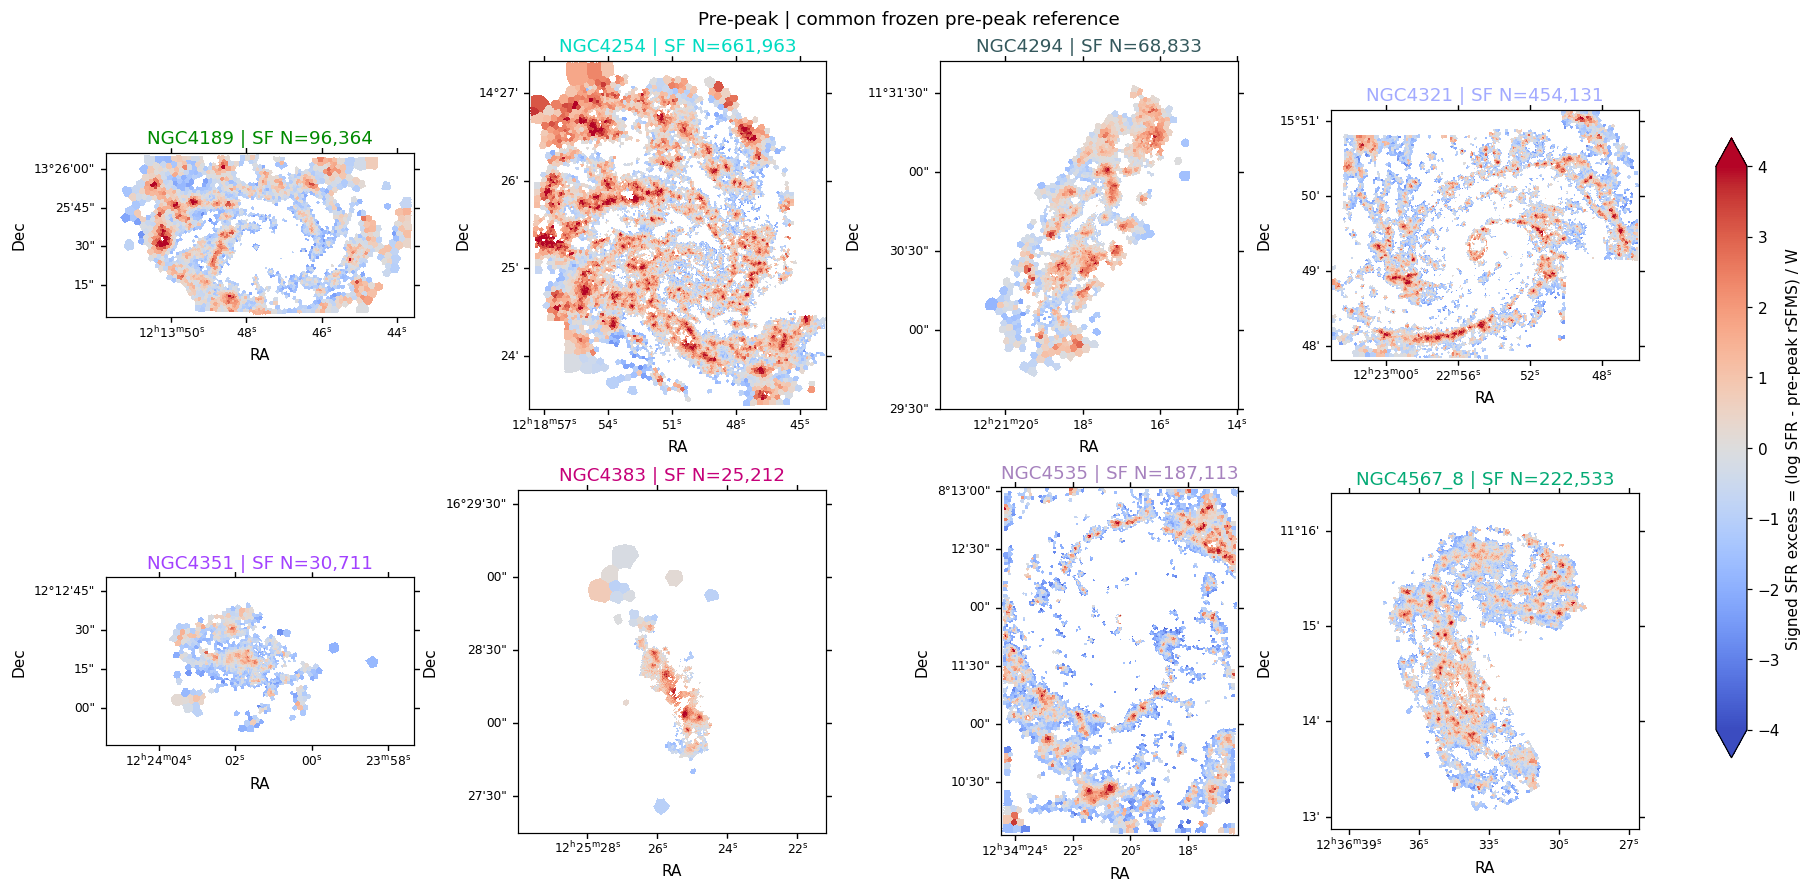

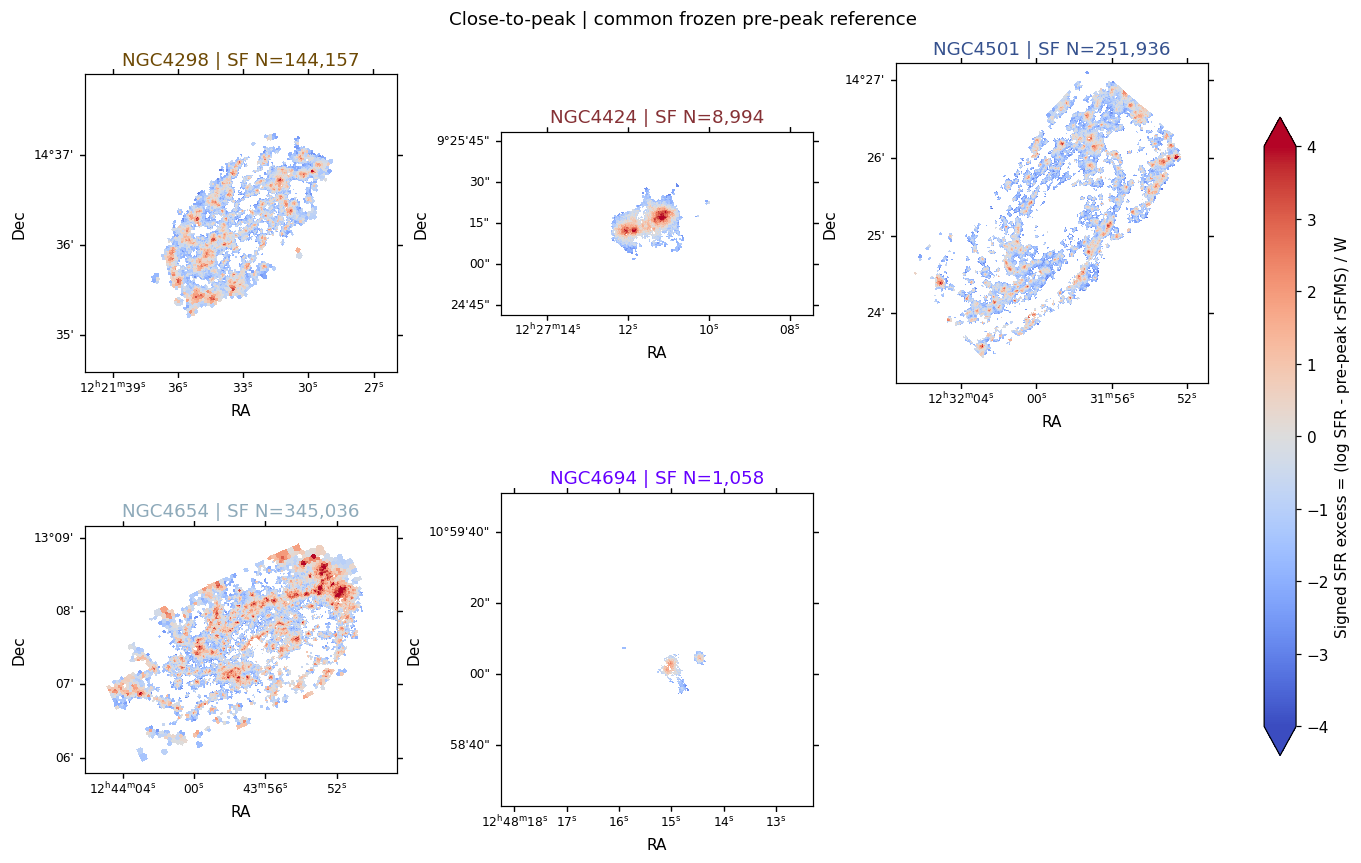

In [9]:
def plot_excess_maps(ids, stage_label):
    ncol = 3 if len(ids) <= 6 else 4
    nrow = int(np.ceil(len(ids)/ncol))
    fig = plt.figure(figsize=(4.1*ncol, 4.0*nrow), layout='constrained')
    axes = []
    for j, g in enumerate(ids):
        maps = galaxy_maps[g]
        ax = fig.add_subplot(nrow,ncol,j+1,projection=WCS(maps['header']).celestial)
        axes.append(ax)
        im = ax.imshow(maps['excess'],origin='lower',cmap='coolwarm',
            vmin=-MAP_LIMIT,vmax=MAP_LIMIT,interpolation='nearest')
        ax.set_title(f'{g} | SF N={len(samples[g]):,}', color=galaxy_colors[g])
        ax.coords[0].set_axislabel('RA')
        ax.coords[1].set_axislabel('Dec')
        ax.coords[0].set_ticklabel(size=8)
        ax.coords[1].set_ticklabel(size=8)
    fig.colorbar(im, ax=axes, shrink=.8, extend='both',
        label='Signed SFR excess = (log SFR - pre-peak rSFMS) / W')
    fig.suptitle(stage_label + ' | common frozen pre-peak reference')
    plt.show()
plot_excess_maps(pre_ids, 'Pre-peak')
plot_excess_maps(close_ids, 'Close-to-peak')

## 1.3. Histogram panels: all pre-peak galaxies plus one close-to-peak

Each galaxy histogram integrates to one using identical bins covering the
entire selected excess range; no histogram tails are dropped. Every panel
shows all selected pre-peak products as thin solid curves and one close-to-peak
galaxy as a thick dashed curve. The black reference is the equal-galaxy mean
pre-peak histogram. Counts and >1/>2/>3 fractions remain in the preceding table.

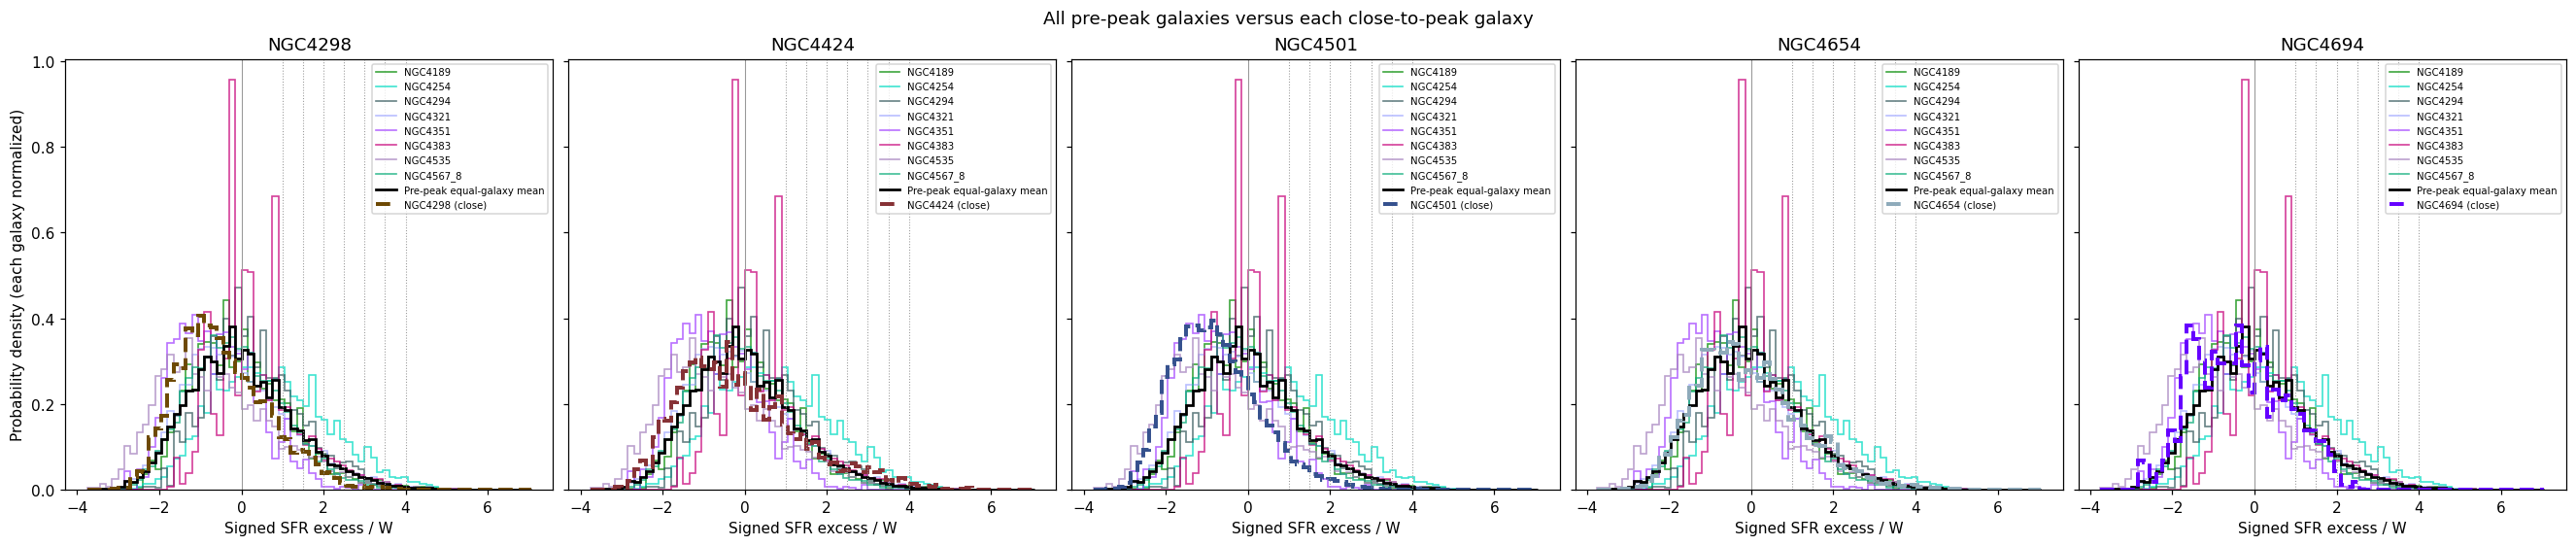

In [10]:
all_excess = np.concatenate([samples[g].excess.to_numpy() for g in pre_ids+close_ids])
bin_step = .15
hist_edges = np.arange(np.floor(all_excess.min()/bin_step)*bin_step,
    np.ceil(all_excess.max()/bin_step)*bin_step+2*bin_step, bin_step)
def histogram_density(g):
    counts, _ = np.histogram(samples[g].excess, bins=hist_edges)
    assert counts.sum() == len(samples[g])
    return counts / counts.sum() / np.diff(hist_edges)
pre_hist = {g: histogram_density(g) for g in pre_ids}
pooled_equal_hist = np.mean(list(pre_hist.values()), axis=0)
fig, axes = plt.subplots(1,len(close_ids),figsize=(24,5),sharex=True,sharey=True,
    layout='constrained')
for ax, close_g in zip(axes, close_ids):
    for g in pre_ids:
        ax.stairs(pre_hist[g],hist_edges,color=galaxy_colors[g],lw=1.1,alpha=.75,label=g)
    ax.stairs(pooled_equal_hist,hist_edges,color='black',lw=1.8,label='Pre-peak equal-galaxy mean')
    ax.stairs(histogram_density(close_g),hist_edges,color=galaxy_colors[close_g],
        lw=2.6,ls='--',label=close_g+' (close)')
    for threshold in (0, *EXCESS_THRESHOLDS):
        ax.axvline(threshold,color='0.6',ls=':' if threshold else '-',lw=.7)
    ax.set(title=close_g, xlabel='Signed SFR excess / W')
    ax.legend(fontsize=6.6,loc='upper right')
axes[0].set_ylabel('Probability density (each galaxy normalized)')
fig.suptitle('All pre-peak galaxies versus each close-to-peak galaxy')
plt.show()

## 2. Frozen reference checks and reading limits

The final checks verify equal fit weights, direct agreement with weighted
least squares, the exact mean-of-per-galaxy width calculation, and threshold
counts/map support. These checks validate the implementation, not a physical
enhancement claim. Shared gas bins and PSF correlations mean native spaxels
are not independent; the fractions describe the observed selected footprint
and have no binomial significance interpretation here. The in-sample pre-peak
width also omits uncertainty in the fitted reference.

In [11]:
design = np.column_stack([x, np.ones_like(x)])
independent_coef = np.linalg.lstsq(design*np.sqrt(weights)[:,None],
    y*np.sqrt(weights),rcond=None)[0]
np.testing.assert_allclose([slope,intercept],independent_coef,rtol=1e-9,atol=1e-9)
direct_width = np.mean([np.mean(np.sqrt(np.maximum(
    (f.y.to_numpy()-rsfms(f.x))**2 - f.sfr_err_dex.to_numpy()**2,0)))
    for g in pre_ids for f in [samples[g].loc[np.isfinite(samples[g].sfr_err_dex)]]])
np.testing.assert_allclose(width_dex,direct_width)
assert set(pre.GALID) == set(pre_ids)
assert not set(pre.GALID) & set(close_ids)
for row in fractions.itertuples(index=False):
    f = samples[row.GALID]
    emap = galaxy_maps[row.GALID]['excess']
    sf = galaxy_maps[row.GALID]['sf_mask']
    assert np.array_equal(np.isfinite(emap),sf)
    np.testing.assert_allclose(emap[sf],f.excess)
    record = fractions.loc[fractions.GALID.eq(row.GALID)].iloc[0]
    counts = [record[f'N_excess_gt{t}'] for t in EXCESS_THRESHOLDS]
    assert row.N_SF >= counts[0] and all(a >= b for a,b in zip(counts,counts[1:]))
    assert all(0 <= record[f'fraction_excess_gt{t}'] <= 1 for t in EXCESS_THRESHOLDS)
    np.testing.assert_allclose(np.sum(histogram_density(row.GALID)*np.diff(hist_edges)),1)
print('CHECKS_OK:',len(pre_ids),'pre-peak products;',len(close_ids),'close-to-peak products')
print('Width:',width_dex,'dex; Python',platform.python_version())
print('No products or external figure/table files written; all figures use plt.show().')

CHECKS_OK: 8 pre-peak products; 5 close-to-peak products
Width: 0.3480022860096287 dex; Python 3.13.3
No products or external figure/table files written; all figures use plt.show().


## 3. Candidate context before directional analysis

The density overlays and full-footprint threshold table above show every selected
close-to-peak product. NGC4654 is the specified case study, not selected by an
automated maximum-tail rule. High fractions in another galaxy must be read
together with SF support and morphology; this notebook does not establish that
NGC4654 is uniquely or objectively the "cleanest" candidate. Native SF counts
describe footprint support rather than independent measurements.

In [12]:
display(fractions.loc[fractions.GALID.isin(close_ids), ['GALID','N_SF']+[f'fraction_excess_gt{t}' for t in EXCESS_THRESHOLDS]+
    ['fraction_outside_reference_x']])
for g,f in samples.items():
    maps=galaxy_maps[g]
    py,px=f.pixel_y.to_numpy(int),f.pixel_x.to_numpy(int)
    f['r']=maps['radius_re'][py,px]
    f['binid']=maps['mass_bin_id'][py,px]
    f['log_ew']=np.log10(maps['ew_ha'][py,px])
target=samples[TARGET].copy()
component=geometry.loc[geometry.notebook_product_id.eq(TARGET)]
assert len(component)==1, 'Fourier azimuth requires a single adopted centre'
geom=component.iloc[0]
ra,dec=WCS(galaxy_maps[TARGET]['header']).celestial.pixel_to_world_values(
    target.pixel_x.to_numpy(),target.pixel_y.to_numpy())
target['east'],target['north']=tangent_offsets_arcsec(ra,dec,geom.center_ra_deg,geom.center_dec_deg)
target['theta']=projected_sky_angle(target.east,target.north)
def sky_pa(phase):
    # Fitted phase already is projected PA; only convert radians to degrees.
    return np.rad2deg(phase)%360
valid_bins=np.isfinite(target.binid)&target.binid.ge(0)&target.binid.eq(np.floor(target.binid))
print('SF spaxels excluded from Fourier for invalid continuum BINID:',int((~valid_bins).sum()))
print('SF spaxels with undefined sky angle:',int((~np.isfinite(target.theta)).sum()))
target_native=target.loc[valid_bins & np.isfinite(target.theta)].copy()
target_native['binid']=target_native.binid.astype(np.int64)
radius=galaxy_maps[TARGET]['radius_re']
print('Maximum valid R/Re:',np.nanmax(radius[galaxy_maps[TARGET]['valid_disc_mask']]))
print('Maximum SF R/Re:',target.r.max())
R_EDGES=np.arange(int(np.floor(target.r.max()/RADIAL_STEP))+2)*RADIAL_STEP
target_native['annulus']=np.searchsorted(R_EDGES,target_native.r,side='right')-1
coverage_rows=[]
for a in range(len(R_EDGES)-1):
    f=target_native.loc[target_native.annulus.eq(a)]
    occupied=len(np.unique(np.floor((f.theta.to_numpy()%(2*np.pi))/(2*np.pi)*N_ANGULAR_SECTORS)))
    accepted=(len(f)>=MIN_PIXELS_ANNULUS and f.binid.nunique()>=MIN_BINS_ANNULUS
        and occupied>=MIN_ANGULAR_SECTORS)
    coverage_rows.append(dict(annulus=a,R_lo=R_EDGES[a],R_hi=R_EDGES[a+1],
        N_SF=len(f),N_BINID=f.binid.nunique(),angular_sectors=occupied,accepted=accepted))
coverage=pd.DataFrame(coverage_rows)
display(coverage)
supported_annuli=coverage.loc[coverage.accepted,'annulus'].tolist()
assert supported_annuli, 'No adequately supported annulus'
fourier_frame=target_native.loc[target_native.annulus.isin(supported_annuli)].copy()
print('Fourier retained SF fraction:',len(fourier_frame)/len(target))

,GALID,N_SF,fraction_excess_gt1,fraction_excess_gt1.5,fraction_excess_gt2,fraction_excess_gt2.5,fraction_excess_gt3,fraction_excess_gt3.5,fraction_excess_gt4,fraction_outside_reference_x
8,NGC4298,144157,0.111954,0.060753,0.024453,0.009386,0.004231,0.000930,0.000236,0.0
9,NGC4424,8994,0.207027,0.141428,0.096064,0.069268,0.042918,0.019902,0.010229,0.0
10,NGC4501,251936,0.061762,0.030369,0.015083,0.005716,0.002251,0.001092,0.000492,0.0
11,NGC4654,345036,0.200026,0.125688,0.070390,0.038416,0.020609,0.011521,0.005570,0.0
12,NGC4694,1058,0.130435,0.058601,0.008507,0.001890,0.000000,0.000000,0.000000,0.0


SF spaxels excluded from Fourier for invalid continuum BINID: 0
SF spaxels with undefined sky angle: 0
Maximum valid R/Re: 2.8366301787072783
Maximum SF R/Re: 2.3740766759221468


,annulus,R_lo,R_hi,N_SF,N_BINID,angular_sectors,accepted
0,0,0.0,0.4,17956,4985,12,True
1,1,0.4,0.8,67658,6723,12,True
2,2,0.8,1.2,86393,3930,12,True
3,3,1.2,1.6,103483,2078,12,True
4,4,1.6,2.0,63444,467,12,True
5,5,2.0,2.4,6102,32,5,False


Fourier retained SF fraction: 0.9823148888811603


## 4. Native-spaxel Fourier fit and BINID resampling

Use projected sky PA theta=atan2(east,north), measured east of north.
No inclination correction or disc-to-sky phase conversion is applied to the
fit or sectors. The inherited elliptical R/Re remains the radial coordinate
for annular control and comparison to pre-peak products. This is a projected
harmonic asymmetry analysis; the coefficients are not intrinsic disc modes.
Inclination can alter the fitted amplitudes and mix harmonic orders.
The native measurements and map coordinates remain observed sky coordinates.

Each supported annulus has its own intercept, radial slope and m=2 terms;
one coherent m=1 coefficient pair spans the accepted annuli. Coverage gates
use positions and counts: at least 9/12 angular sectors, 30 native SF spaxels,
and 20 continuum BINIDs per annulus. The BINID gate replaces the old coarse-cell
sample-size gate. No R<1.6 Re cut is applied.

Within the retained fitting population w_i=1/N_selected,BINID, so each continuum
BINID has unit total weight. The whole BINID is resampled once across all
annuli. The null is separately fitted m=0+m=2; a restricted wild bootstrap
multiplies each BINID's null residual vector by one random sign. Compare the
weighted RSS gain from adding m=1. This is approximate conditional inference:
BINID boundaries need not capture all gas-bin/PSF correlation, and the frozen
pre-peak line and W have uncertainty not included in these intervals.

Only normalized excess E is fitted and displayed here. A positive amplitude CI
is not a detection test because amplitude is nonnegative.

### Functional form and simultaneous fit

For spaxel i in annulus a, with r=R/Re and midpoint r_a:

$$\widehat E_i=\alpha_a+\beta_a(r_i-r_a)
+c_{2,a}\cos(2\theta_i)+s_{2,a}\sin(2\theta_i)
+c_1\cos\theta_i+s_1\sin\theta_i.$$

The null model omits the last two terms and refits all annular coefficients.
There are 4K+2 full-model parameters and 4K null parameters for K supported
annuli. The counts printed below follow the current supported-annulus set. The shared m=1
**amplitude and phase are both common across annuli**, not just the phase:

$$A_1=\sqrt{c_1^2+s_1^2},\qquad\theta_1=\operatorname{atan2}(s_1,c_1).$$

Neither is fixed to a prescribed direction. Every annular coefficient and the
shared pair are estimated together. Build a single design matrix whose four
annulus-specific columns are zero outside their annulus; its final two columns
are cos(theta) and sin(theta) for every row. Minimize

$$Q(\boldsymbol{b})=\sum_i w_i[E_i-(X\boldsymbol{b})_i]^2,
\qquad w_i=1/N_{\mathrm{selected},\mathrm{BINID}(i)}.$$

The code uses `scipy.optimize.least_squares(method="lm")` (Levenberg-Marquardt)
with an analytic Jacobian and a zero initial coefficient vector. The Fourier
basis remains linear in its coefficients. QR compression of the weighted
native design and Cholesky factors of BINID sufficient statistics preserve
the same least-squares minimum while avoiding repeated large residual arrays.
Full, null, whole-BINID bootstrap and wild-bootstrap fits all use LM; solver
failures are reported. Amplitude and phase are derived after fitting.
The frozen pre-peak rSFMS reference fit is unchanged.

### What goodness of fit means here

Weighted RMSE is sqrt(Q/sum(w)), in units of W. Weighted R2 compares Q to the
weighted scatter about a constant mean; it is descriptive and includes radial
structure. The full-versus-null fractional RSS reduction isolates the gain from
adding the shared m=1 pair. Per-annulus metrics show where the model fits better
or worse. These are in-sample descriptions, not predictive validation.

The wild-bootstrap p-value tests whether m=1 improves the null model; it does
**not** mean the full model closely describes every spaxel. There is no reduced
chi-square because the fitting weights balance BINIDs rather than represent
inverse measurement variances, and residual spatial dependence remains.

### Side-by-side model p-values

The model-comparison table reports weighted R2 and RMSE for both alternatives.
Each overall p-value tests that model against the **same single constant-only
model**, using whole-BINID wild resampling of the constant model's residuals.
Both alternatives and the constant are refitted in each draw. These global
tests include radial variation, annular offsets and m=2 structure; a small
overall p-value does not attribute the improvement to m=1.

The separate incremental p-value tests adding the two shared m=1 coefficients
to the freely fitted annular m=0+2 null. These are different null hypotheses.
The global p-values are not repeated as independent per-annulus detections.
All tests are approximate and conditional on fixed radial support/reference.


In [13]:
def angle_difference(a,b): return (np.asarray(a)-b+np.pi)%(2*np.pi)-np.pi

def native_design(frame,annuli,include_m1=True):
    cols=[]
    for a in annuli:
        take=frame.annulus.eq(a).to_numpy(float)
        cols.extend([take,take*(frame.r.to_numpy()-(a+.5)*RADIAL_STEP),
            take*np.cos(2*frame.theta),take*np.sin(2*frame.theta)])
    if include_m1: cols.extend([np.cos(frame.theta),np.sin(frame.theta)])
    return np.column_stack(cols)

def levmar_factor(R, values):
    """Minimize ||R beta-values|| with Levenberg-Marquardt."""
    result=least_squares(lambda beta: np.einsum('ij,j->i',R,beta)-values, np.zeros(R.shape[1]),
        jac=lambda beta: R, method='lm', x_scale='jac',
        ftol=1e-12, xtol=1e-12, gtol=1e-12, max_nfev=200)
    if not result.success or not np.isfinite(result.x).all():
        raise RuntimeError('Levenberg-Marquardt Fourier fit failed: '+result.message)
    return result.x

def levmar_gram(G, rhs):
    """Cholesky compression preserves the weighted least-squares minimum."""
    R=np.linalg.cholesky(G).T
    return levmar_factor(R,np.linalg.solve(R.T,rhs))

def fit_native_fourier(frame,value,nboot=499,nnull=999,seed=20261012):
    f=frame.loc[np.isfinite(frame[value])].copy().reset_index(drop=True)
    annuli=sorted(f.annulus.unique())
    labels,ix=np.unique(f.binid,return_inverse=True)
    if len(labels)<MIN_BINS_FIT: raise ValueError('Too few BINIDs for Fourier inference')
    count=np.bincount(ix)
    w=1/count[ix]
    f['weight']=w
    X=native_design(f,annuli)
    y=f[value].to_numpy(float)
    xw=X*np.sqrt(w)[:,None]
    rank=np.linalg.matrix_rank(xw)
    condition=np.linalg.cond(xw)
    if rank!=X.shape[1] or condition>MAX_DESIGN_CONDITION:
        raise ValueError('Rank-deficient or poorly conditioned Fourier fit')
    q,R=np.linalg.qr(xw,mode="reduced")
    beta=levmar_factor(R,np.einsum('ni,n->i',q,y*np.sqrt(w)))
    p=X.shape[1]
    # BINID sufficient statistics keep native rows without repeated large fits.
    gb=np.empty((len(labels),p,p)); hb=np.empty((len(labels),p))
    for j in range(p):
        hb[:,j]=np.bincount(ix,weights=w*X[:,j]*y,minlength=len(labels))
        for k in range(j+1):
            gb[:,j,k]=gb[:,k,j]=np.bincount(ix,weights=w*X[:,j]*X[:,k],minlength=len(labels))
    G=gb.sum(axis=0); h=hb.sum(axis=0)
    Rfull=np.linalg.cholesky(G).T; Rnull=np.linalg.cholesky(G[:-2,:-2]).T
    beta0=levmar_factor(Rnull,np.linalg.solve(Rnull.T,h[:-2]))
    fitted=np.einsum('ij,j->i',X,beta)
    fitted0=np.einsum('ij,j->i',X[:,:-2],beta0)
    rss=np.sum(w*(y-fitted)**2); rss0=np.sum(w*(y-fitted0)**2)
    gain=max(0.,rss0-rss)
    def improvement(rhs):
        full=levmar_factor(Rfull,np.linalg.solve(Rfull.T,rhs))
        without=levmar_factor(Rnull,np.linalg.solve(Rnull.T,rhs[:-2]))
        return float((2*np.dot(rhs,full)-np.einsum('i,ij,j->',full,G,full))-
            (2*np.dot(rhs[:-2],without)-np.einsum('i,ij,j->',without,G[:-2,:-2],without)))
    np.testing.assert_allclose(gain,improvement(h),rtol=1e-7,atol=1e-7)
    rng=np.random.default_rng(seed)
    draws=[]
    for _ in range(nboot):
        mult=np.bincount(rng.integers(len(labels),size=len(labels)),minlength=len(labels))
        gg=np.einsum('b,bij->ij',mult,gb); hh=np.einsum('b,bi->i',mult,hb)
        if np.linalg.cond(gg)>MAX_DESIGN_CONDITION**2: continue
        try: draws.append(levmar_gram(gg,hh)[-2:])
        except np.linalg.LinAlgError: continue
    if len(draws)<.9*nboot: raise ValueError('More than 10% BINID bootstrap fits failed')
    draws=np.asarray(draws)
    score=np.column_stack([np.bincount(ix,weights=w*X[:,j]*(y-fitted0),minlength=len(labels)) for j in range(p)])
    null_mean=np.einsum('ij,j->i',G[:,:-2],beta0)
    null=np.array([improvement(null_mean+np.einsum('b,bi->i',rng.choice([-1.,1.],len(labels)),score)) for _ in range(nnull)])
    amp=float(np.hypot(*beta[-2:])); phase=float(np.arctan2(beta[-1],beta[-2]))
    boot_amp=np.hypot(draws[:,0],draws[:,1]); boot_phase=np.arctan2(draws[:,1],draws[:,0])
    return dict(frame=f,annuli=annuli,beta=beta,beta0=beta0,X=X,weight=w,
        fitted=fitted,fitted0=fitted0,amplitude=amp,phase=phase,
        amplitude_ci=np.quantile(boot_amp,[.025,.975]),phase_draws=boot_phase,
        phase_offset_ci=np.rad2deg(np.quantile(angle_difference(boot_phase,phase),[.025,.975])),
        phase_resultant=abs(np.mean(np.exp(1j*boot_phase))),
        p_wild=(1+np.sum(null>=gain-1e-9))/(nnull+1),gain=gain,null=null,
        rss=rss,rss0=rss0,condition=condition,failed_boot=nboot-len(draws))

def overall_model_tests(res,nnull=999,seed=20261013):
    """BINID restricted wild tests of both global models vs one constant."""
    X=res['X'];w=res['weight'];y=res['frame'].excess.to_numpy()
    labels,ix=np.unique(res['frame'].binid,return_inverse=True)
    mean=np.average(y,weights=w)
    G=np.einsum('ni,n,nj->ij',X,w,X)
    Rfull=np.linalg.cholesky(G).T; Rnull=np.linalg.cholesky(G[:-2,:-2]).T
    hmean=np.einsum('ni,n->i',X,w)*mean
    score=np.column_stack([np.bincount(ix,weights=w*X[:,j]*(y-mean),minlength=len(labels))
        for j in range(X.shape[1])])
    def gains(rhs):
        # Sum the disjoint annular-intercept RHS entries to refit the common
        # constant in every bootstrap draw. Both alternatives use that baseline.
        constant_gain=np.sum(rhs[:-2:4])**2/w.sum()
        beta=levmar_factor(Rfull,np.linalg.solve(Rfull.T,rhs))
        beta0=levmar_factor(Rnull,np.linalg.solve(Rnull.T,rhs[:-2]))
        full=2*np.dot(rhs,beta)-np.einsum('i,ij,j->',beta,G,beta)-constant_gain
        without=2*np.dot(rhs[:-2],beta0)-np.einsum('i,ij,j->',beta0,G[:-2,:-2],beta0)-constant_gain
        return np.array([full,without])
    rss_constant=np.sum(w*(y-mean)**2)
    observed=np.array([rss_constant-res['rss'],rss_constant-res['rss0']])
    rng=np.random.default_rng(seed)
    null=np.array([gains(hmean+np.einsum('b,bi->i',rng.choice([-1.,1.],len(labels)),score))
        for _ in range(nnull)])
    p=(1+np.sum(null>=observed[None,:]-1e-9,axis=0))/(nnull+1)
    return dict(p_full_vs_constant=float(p[0]),p_without_m1_vs_constant=float(p[1]),
        draws=nnull,baseline='One weighted constant across all supported annuli')


In [14]:
results={}
fit_rows=[]
for j,value in enumerate(['excess']):
    print('Fitting',value,flush=True)
    res=fit_native_fourier(fourier_frame,value,N_BOOT,N_NULL,SEED+j)
    results[value]=res
    pa=sky_pa(res['phase'])
    pa_offsets=(sky_pa(res['phase_draws'])-pa+180)%360-180
    fit_rows.append(dict(observable=value,role='primary' if value=='excess' else 'sensitivity',
        amplitude=res['amplitude'],units='W' if value=='excess' else 'dex',
        A1_lo=res['amplitude_ci'][0],A1_hi=res['amplitude_ci'][1],
        peak_opposite_m1=2*res['amplitude'],theta_sky_deg=np.rad2deg(res['phase'])%360,
        PA_sky_deg=pa,PA_offset_lo=np.quantile(pa_offsets,.025),PA_offset_hi=np.quantile(pa_offsets,.975),
        phase_resultant=res['phase_resultant'],p_wild=res['p_wild'],
        N_SF=len(res['frame']),N_BINID=res['frame'].binid.nunique(),
        weighted_RMSE=np.sqrt(res['rss']/res['weight'].sum()),
        relative_RSS_gain=res['gain']/res['rss0'],failed_boot=res['failed_boot'],condition=res['condition']))
fit_summary=pd.DataFrame(fit_rows)
display(fit_summary.set_index('observable').T)
primary=results['excess']
fixed_phase=primary['phase']
print('Primary conditional m=1 detection:',primary['p_wild']<=ALPHA)
print('Primary amplitude in dex:',primary['amplitude']*width_dex)
print('Phase is estimated from E; no expected sky direction was used.')

# Best-fitting full-model coefficients, in exactly the design-matrix order.
parameter_rows=[]
for k,a in enumerate(primary['annuli']):
    alpha,beta,c2,s2=primary['beta'][4*k:4*k+4]
    parameter_rows.append(dict(annulus=a,R_lo=R_EDGES[a],R_hi=R_EDGES[a+1],
        r_mid=(R_EDGES[a]+R_EDGES[a+1])/2,alpha_W=alpha,beta_W_per_Re=beta,
        c2_W=c2,s2_W=s2,A2_W=np.hypot(c2,s2),
        theta2_sky_deg=(np.rad2deg(np.arctan2(s2,c2))/2)%180))
best_parameters=pd.DataFrame(parameter_rows)
shared_parameters=pd.DataFrame([dict(c1_W=primary['beta'][-2],s1_W=primary['beta'][-1],
    A1_W=primary['amplitude'],theta1_sky_deg=np.rad2deg(fixed_phase)%360,
    PA1_sky_deg=sky_pa(fixed_phase))])
print('Full-model annular coefficients: alpha,c2,s2 in W; beta in W per unit R/Re')
display(best_parameters.round(6))
print('Shared m=1 coefficients (estimated jointly with every annulus):')
display(shared_parameters.round(6))
print('Model parameter counts: full',len(primary['beta']),'null',len(primary['beta0']))

def goodness_row(take,label):
    f=primary['frame'].loc[take]; w=primary['weight'][take]
    y=f.excess.to_numpy()
    rss=np.sum(w*(y-primary['fitted'][take])**2)
    rss0=np.sum(w*(y-primary['fitted0'][take])**2)
    tss=np.sum(w*(y-np.average(y,weights=w))**2)
    return dict(radial_scope=label,N_SF=len(f),N_BINID=f.binid.nunique(),
        weighted_RMSE_full_W=np.sqrt(rss/w.sum()),
        weighted_RMSE_null_W=np.sqrt(rss0/w.sum()),
        weighted_R2_full=1-rss/tss if tss>0 else np.nan,
        weighted_R2_null=1-rss0/tss if tss>0 else np.nan,
        RSS_gain_fraction=1-rss/rss0 if rss0>0 else np.nan)
goodness_rows=[goodness_row(np.ones(len(primary['frame']),dtype=bool),'All supported annuli')]
for a in primary['annuli']:
    goodness_rows.append(goodness_row(primary['frame'].annulus.eq(a).to_numpy(),
        f'{R_EDGES[a]:.1f}-{R_EDGES[a+1]:.1f} Re'))
goodness=pd.DataFrame(goodness_rows)
display(goodness.round(6))
print(goodness.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print(best_parameters.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print(shared_parameters.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Per-annulus RSS gains can be negative: all coefficients minimize the global objective, not each annulus separately.')


overall_tests=overall_model_tests(primary,N_NULL,SEED+100)
global_goodness=goodness.iloc[0]
model_comparison=pd.DataFrame([
    dict(model='With m=1 (m=0+1+2)',parameters=len(primary['beta']),
        weighted_R2=global_goodness.weighted_R2_full,
        weighted_RMSE_W=global_goodness.weighted_RMSE_full_W,
        p_vs_constant=overall_tests['p_full_vs_constant']),
    dict(model='Without m=1 (m=0+2)',parameters=len(primary['beta0']),
        weighted_R2=global_goodness.weighted_R2_null,
        weighted_RMSE_W=global_goodness.weighted_RMSE_null_W,
        p_vs_constant=overall_tests['p_without_m1_vs_constant'])])
print('Overall model p-values: same constant-only baseline, whole-BINID wild resampling.')
display(model_comparison)
print(model_comparison.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Separate incremental test, adding m=1 to m=0+2: p=',primary['p_wild'])


Fitting excess


observable,excess
role,primary
amplitude,0.204852
units,W
A1_lo,0.185086
A1_hi,0.22762
peak_opposite_m1,0.409703
theta_sky_deg,295.682725
PA_sky_deg,295.682725
PA_offset_lo,-8.837185
PA_offset_hi,10.746588


Primary conditional m=1 detection: True
Primary amplitude in dex: 0.07128882096208625
Phase is estimated from E; no expected sky direction was used.
Full-model annular coefficients: alpha,c2,s2 in W; beta in W per unit R/Re


,annulus,R_lo,R_hi,r_mid,alpha_W,beta_W_per_Re,c2_W,s2_W,A2_W,theta2_sky_deg
0,0,0.0,0.4,0.2,-0.102316,-5.413028,-0.159789,-0.304832,0.344173,121.168526
1,1,0.4,0.8,0.6,-0.031181,0.856458,0.148903,0.041810,0.154662,7.842072
2,2,0.8,1.2,1.0,0.071493,-0.563186,0.003648,-0.136642,0.136690,135.764605
3,3,1.2,1.6,1.4,-0.053196,-3.043096,-0.193930,-0.795800,0.819089,128.152218
4,4,1.6,2.0,1.8,0.059185,-0.854592,-0.057240,0.026707,0.063164,77.493653


Shared m=1 coefficients (estimated jointly with every annulus):


...

Model parameter counts: full 22 null 20


,radial_scope,N_SF,N_BINID,weighted_RMSE_full_W,weighted_RMSE_null_W,weighted_R2_full,weighted_R2_null,RSS_gain_fraction
0,All supported annuli,338934,17523,1.230445,1.242161,0.123469,0.106697,0.018775
1,0.0-0.4 Re,17956,4985,1.018678,1.031872,0.232960,0.212962,0.025410
2,0.4-0.8 Re,67658,6723,1.191531,1.178560,-0.008214,0.013619,-0.022134
3,0.8-1.2 Re,86393,3930,1.386086,1.416798,0.052410,0.009953,0.042884
4,1.2-1.6 Re,103483,2078,1.495592,1.536667,0.211909,0.168027,0.052745
5,1.6-2.0 Re,63444,467,1.273808,1.287626,0.037923,0.016937,0.021348


        radial_scope   N_SF  N_BINID  weighted_RMSE_full_W  weighted_RMSE_null_W  weighted_R2_full  weighted_R2_null  RSS_gain_fraction
All supported annuli 338934    17523              1.230445              1.242161          0.123469          0.106697           0.018775
          0.0-0.4 Re  17956     4985              1.018678              1.031872          0.232960          0.212962           0.025410
          0.4-0.8 Re  67658     6723              1.191531              1.178560         -0.008214          0.013619          -0.022134
          0.8-1.2 Re  86393     3930              1.386086              1.416798          0.052410          0.009953           0.042884
          1.2-1.6 Re 103483     2078              1.495592              1.536667          0.211909          0.168027           0.052745
          1.6-2.0 Re  63444      467              1.273808              1.287626          0.037923          0.016937           0.021348
 annulus     R_lo     R_hi    r_mid   alpha_W  b

,model,parameters,weighted_R2,weighted_RMSE_W,p_vs_constant
0,With m=1 (m=0+1+2),22,0.123469,1.230445,0.001
1,Without m=1 (m=0+2),20,0.106697,1.242161,0.001


              model  parameters  weighted_R2  weighted_RMSE_W  p_vs_constant
 With m=1 (m=0+1+2)          22     0.123469         1.230445       0.001000
Without m=1 (m=0+2)          20     0.106697         1.242161       0.001000
Separate incremental test, adding m=1 to m=0+2: p= 0.001


## 5. Observed measurements versus fitted projected sky PA

All native measurements are retained in the fit. For display subtract only the
full model's within-annulus radial slope: Ycorr=Y-beta_a(R-Rmid).
The full curve is evaluated at Rmid. The separately fitted null has its own
radial slope; its displayed prediction at each native point is corrected by the
**same full-model slope**, then averaged in angular bins. This compares both
models to the same transformed observations without silently replacing the null
slope by the full slope. The null line therefore reflects sampled radial
coverage. Weighted 20-degree means are visual summaries, not a refit.

All supported annuli appear together in a single excess-only figure. Each panel
shows its weighted full/null RMSE, computed on the original native E values
before the display-only radial correction.

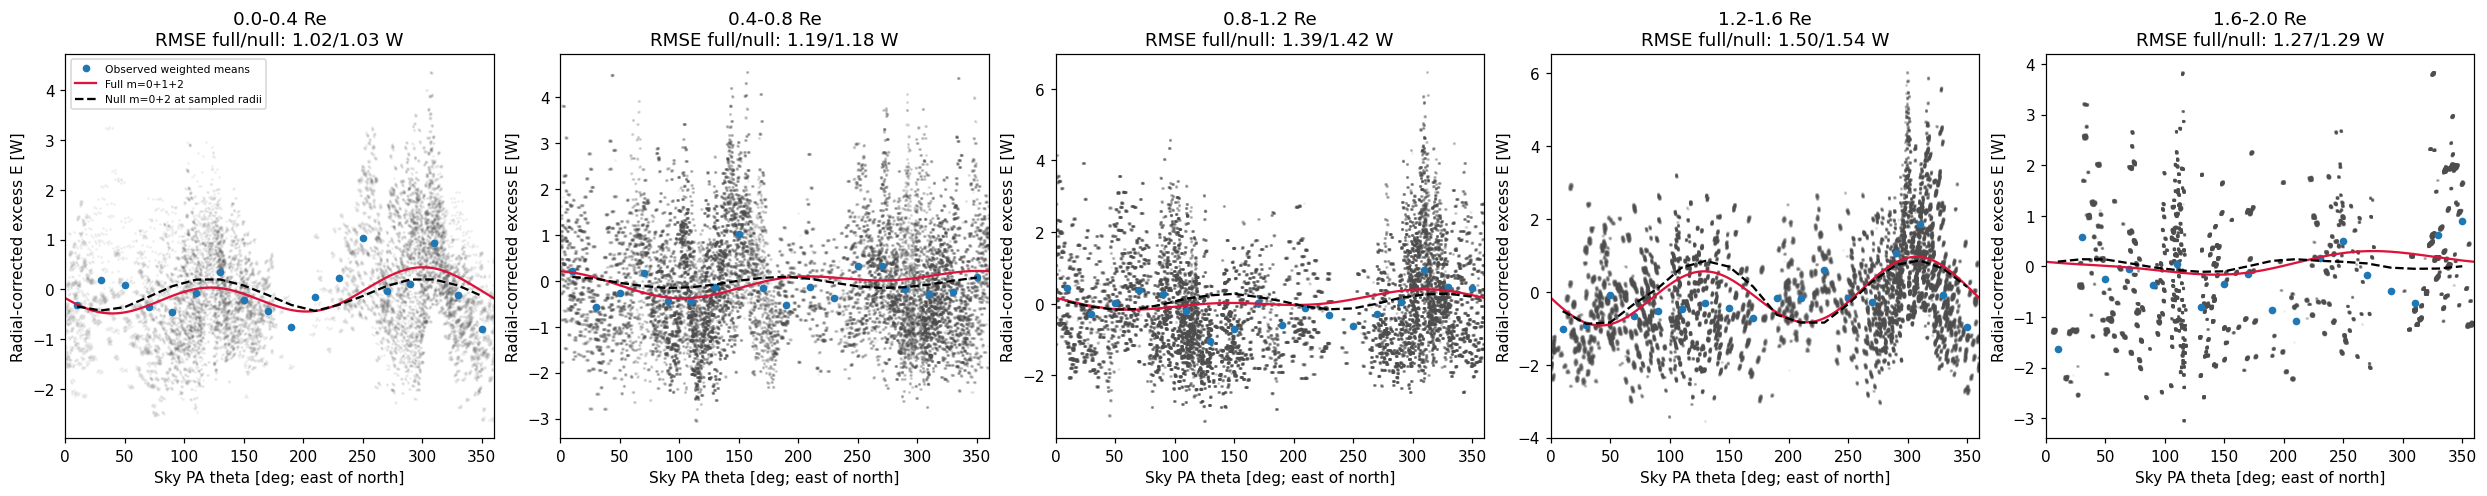

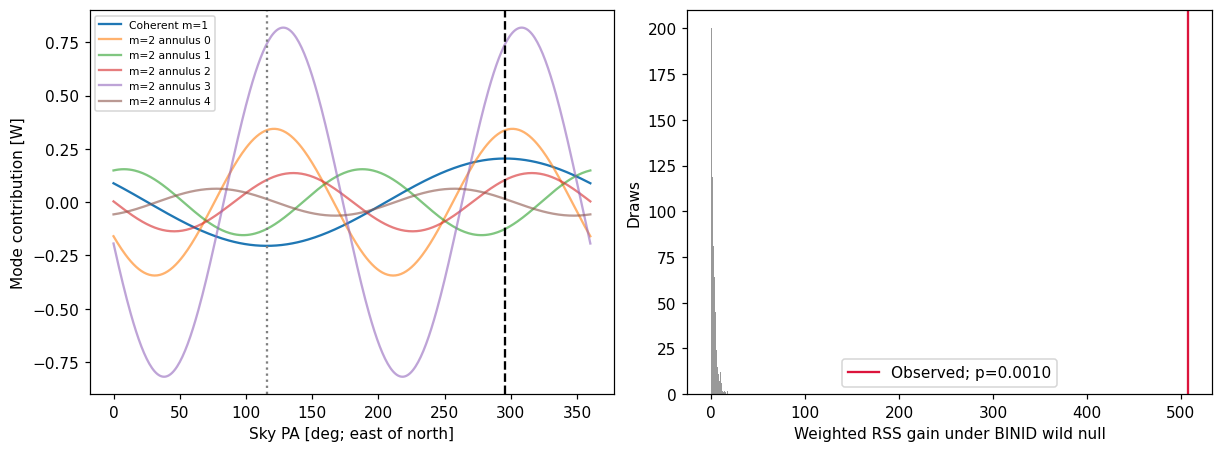

In [15]:
angle_edges=np.linspace(0,2*np.pi,19)
angle_centres=np.rad2deg((angle_edges[:-1]+angle_edges[1:])/2)
def angular_means(phi,value,weight):
    idx=np.minimum(np.searchsorted(angle_edges,phi%(2*np.pi),side='right')-1,17)
    num=np.bincount(idx,weights=weight*value,minlength=18)
    den=np.bincount(idx,weights=weight,minlength=18)
    return np.divide(num,den,out=np.full(18,np.nan),where=den>0)
annuli=primary['annuli']
fig,axes=plt.subplots(1,len(annuli),figsize=(4.5*len(annuli),4.4),squeeze=False,layout='constrained')
res=primary; f=res['frame']; phi_grid=np.linspace(0,2*np.pi,361)
for col,a in enumerate(annuli):
    ax=axes[0,col]; take=f.annulus.eq(a).to_numpy(); z=f.loc[take]
    j=res['annuli'].index(a)*4; b=res['beta']
    correction=b[j+1]*(z.r.to_numpy()-(a+.5)*RADIAL_STEP)
    obs=z.excess.to_numpy()-correction
    null_corr=res['fitted0'][take]-correction
    ax.scatter(np.rad2deg(z.theta%(2*np.pi)),obs,s=1,alpha=.05,color='0.3',rasterized=True)
    ax.plot(angle_centres,angular_means(z.theta.to_numpy(),obs,z.weight.to_numpy()),'o',ms=4,label='Observed weighted means')
    curve=b[j]+b[j+2]*np.cos(2*phi_grid)+b[j+3]*np.sin(2*phi_grid)+b[-2]*np.cos(phi_grid)+b[-1]*np.sin(phi_grid)
    ax.plot(np.rad2deg(phi_grid),curve,label='Full m=0+1+2',color='crimson')
    ax.plot(angle_centres,angular_means(z.theta.to_numpy(),null_corr,z.weight.to_numpy()),'--',color='black',label='Null m=0+2 at sampled radii')
    metric=goodness.iloc[col+1]
    ax.set(title=f'{R_EDGES[a]:.1f}-{R_EDGES[a+1]:.1f} Re\nRMSE full/null: {metric.weighted_RMSE_full_W:.2f}/{metric.weighted_RMSE_null_W:.2f} W',
        xlabel='Sky PA theta [deg; east of north]',ylabel='Radial-corrected excess E [W]',xlim=(0,360))
    if col==0: ax.legend(fontsize=7)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
grid=np.linspace(0,2*np.pi,361)
axes[0].plot(np.rad2deg(grid),primary['amplitude']*np.cos(grid-fixed_phase),label='Coherent m=1')
for a in primary['annuli']:
    j=primary['annuli'].index(a)*4
    axes[0].plot(np.rad2deg(grid),primary['beta'][j+2]*np.cos(2*grid)+primary['beta'][j+3]*np.sin(2*grid),alpha=.6,label=f'm=2 annulus {a}')
axes[0].axvline(np.rad2deg(fixed_phase)%360,color='black',ls='--')
axes[0].axvline((np.rad2deg(fixed_phase)+180)%360,color='0.5',ls=':')
axes[0].set(xlabel='Sky PA [deg; east of north]',ylabel='Mode contribution [W]');axes[0].legend(fontsize=7)
axes[1].hist(primary['null'],bins=35,color='0.6')
axes[1].axvline(primary['gain'],color='crimson',label=f"Observed; p={primary['p_wild']:.4f}")
axes[1].set(xlabel='Weighted RSS gain under BINID wild null',ylabel='Draws');axes[1].legend()
plt.show()

## 6. Frozen phase: peak/opposite sectors and external tail context

Define the strict projected sky sectors abs(wrap(theta-theta1))<45 deg and
abs(wrap(theta-theta1-pi))<45 deg. The peak sector is centred on the freely fitted sky PA, not fixed in advance
to NW. If it lies near 315 degrees it approximately corresponds to a sky NW
quadrant. Sector boundaries no longer depend on the disc axis ratio. The phase
is fitted on supported annuli; full-footprint sectors extend that fixed direction
to all native SF spaxels, including unsupported radii. Further analysis has two cases: full footprint and Fourier-selected sky
sectors. Both use the same full-footprint pre-peak reference. The sector case
selects target peak/opposite angles over its full SF footprint, without
radial-support or outer-disc cuts. Pre-peak products have no fitted sector.

Report SF-spaxel fractions, integer counts and undefined empty selections.
BINID-weighted fractions recompute 1/N within each reported population, giving
each represented continuum bin one total vote. Full-footprint area fractions
preserve the source rSFMS comparison. Equal-product pre-peak rows average the
individual fractions, never pool all pixels. Spread across products is a
descriptive population range, not a confidence interval. The sector and full-footprint control populations can have different radial
distributions and other confounders.

The sector tail is measured from the data used to choose the phase: it is
descriptive localization, not an independent external-enhancement p-value.

,population,selection_scope,N_SF,F_gt1,F_gt1.5,F_gt2,F_gt2.5,F_gt3,F_gt3.5,F_gt4
0,NGC4189,Full footprint,96364,0.184197,0.096779,0.052966,0.028880,0.016303,0.008509,0.005666
1,NGC4254,Full footprint,661963,0.397755,0.285563,0.182477,0.110308,0.065676,0.030941,0.014341
2,NGC4294,Full footprint,68833,0.238577,0.139642,0.073468,0.038949,0.011245,0.003908,0.000799
3,NGC4321,Full footprint,454131,0.196542,0.122073,0.072499,0.041484,0.022522,0.010627,0.004915
4,NGC4351,Full footprint,30711,0.080167,0.026961,0.006317,0.003321,0.000098,0.000000,0.000000
5,NGC4383,Full footprint,25212,0.206211,0.127241,0.075361,0.041012,0.021458,0.008805,0.003768
6,NGC4535,Full footprint,187113,0.141503,0.092297,0.052642,0.029218,0.015173,0.007332,0.003094
7,NGC4567_8,Full footprint,222533,0.167795,0.088144,0.043221,0.019939,0.008938,0.004089,0.001407
8,NGC4189,Fourier-selected sectors,96364,0.184197,0.096779,0.052966,0.028880,0.016303,0.008509,0.005666
9,NGC4254,Fourier-selected sectors,661963,0.397755,0.285563,0.182477,0.110308,0.065676,0.030941,0.014341


,population,selection_scope,N_SF,N_BINID,median_E,F_gt1,F_gt1.5,F_gt2,F_gt2.5,F_gt3,F_gt3.5,F_gt4
0,Pre-peak equal-product mean,Full footprint,NaN,NaN,NaN,0.201594,0.122338,0.069869,0.039139,0.020176,0.009277,0.004249
1,NGC4654 full,Full footprint,345036.0,17535.0,-0.207539,0.200026,0.125688,0.070390,0.038416,0.020609,0.011521,0.005570
2,Pre-peak equal-product mean,Fourier-selected sectors,NaN,NaN,NaN,0.201594,0.122338,0.069869,0.039139,0.020176,0.009277,0.004249
3,NGC4654 peak sector,Fourier-selected sectors,124549.0,7515.0,0.126847,0.261776,0.183165,0.111651,0.069170,0.043116,0.028101,0.014187
4,NGC4654 opposite sector,Fourier-selected sectors,125750.0,6611.0,-0.431049,0.147380,0.086624,0.041153,0.018314,0.006744,0.002076,0.000779


,population,selection_scope,N_SF_valid_BINID,F_BIN_gt1,F_BIN_gt1.5,F_BIN_gt2,F_BIN_gt2.5,F_BIN_gt3,F_BIN_gt3.5,F_BIN_gt4
0,Pre-peak equal-product mean,Full footprint,NaN,0.292239,0.189909,0.114107,0.063668,0.033570,0.016718,0.008267
1,NGC4654 full,Full footprint,345036.0,0.223553,0.140519,0.082407,0.044597,0.023382,0.013459,0.007870
2,Pre-peak equal-product mean,Fourier-selected sectors,NaN,0.292239,0.189909,0.114107,0.063668,0.033570,0.016718,0.008267
3,NGC4654 peak sector,Fourier-selected sectors,124549.0,0.269328,0.182834,0.118829,0.068663,0.040585,0.026347,0.016500
4,NGC4654 opposite sector,Fourier-selected sectors,125750.0,0.192255,0.114052,0.054757,0.025110,0.009378,0.003177,0.001361


selection_scope,Full footprint,Fourier-selected sectors
N_products,8.000000,8.000000
F_gt1,0.201594,0.201594
F_gt1_p16,0.144658,0.144658
F_gt1_p84,0.234693,0.234693
F_gt1_min,0.080167,0.080167
F_gt1_max,0.397755,0.397755
F_gt1.5,0.122338,0.122338
F_gt1.5_p16,0.088643,0.088643
F_gt1.5_p84,0.138154,0.138154
F_gt1.5_min,0.026961,0.026961


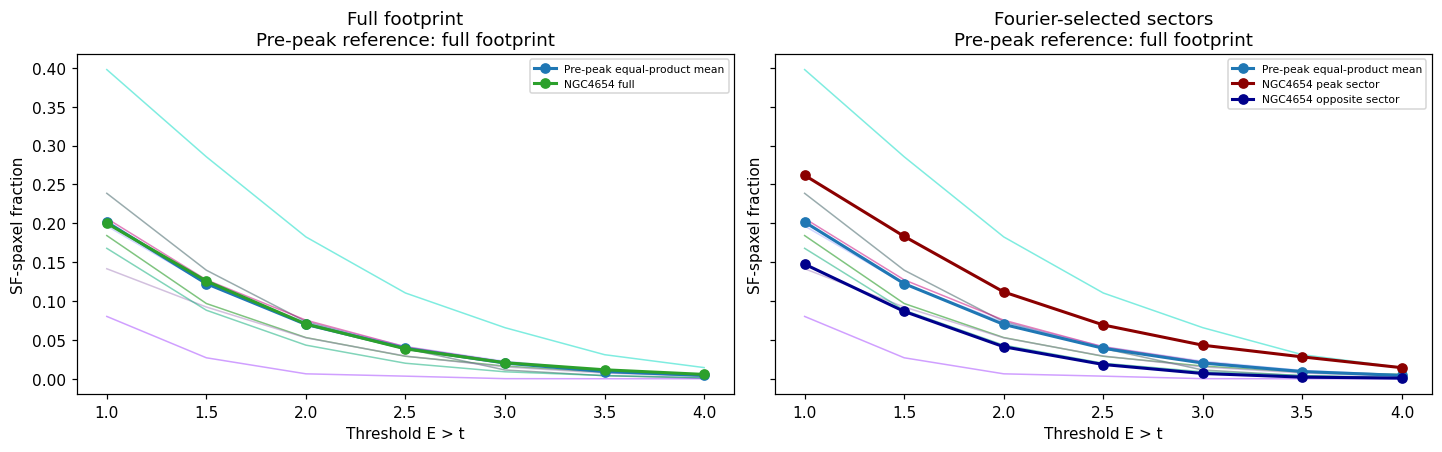

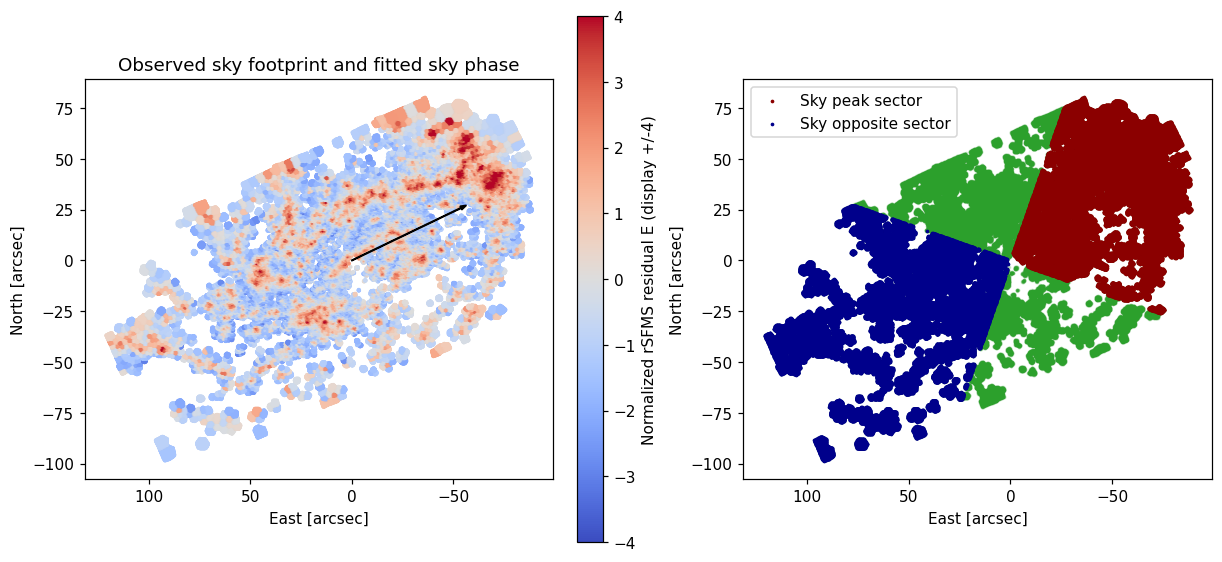

In [16]:
target['peak_sector']=np.abs(angle_difference(target.theta,fixed_phase))<np.deg2rad(SECTOR_HALF_WIDTH_DEG)
target['opposite_sector']=np.abs(angle_difference(target.theta,fixed_phase+np.pi))<np.deg2rad(SECTOR_HALF_WIDTH_DEG)
target['annulus']=np.searchsorted(R_EDGES,target.r,side='right')-1
assert not (target.peak_sector & target.opposite_sector).any()
def population_stats(f,label,selection_scope):
    row=dict(population=label,selection_scope=selection_scope,N_SF=len(f),N_BINID=f.loc[f.binid.ge(0),'binid'].nunique(),
        median_E=f.excess.median(),mean_E=f.excess.mean(),fraction_outside_reference_x=f.outside_reference_x.mean())
    good=np.isfinite(f.binid)&f.binid.ge(0)&f.binid.eq(np.floor(f.binid))
    z=f.loc[good]
    w=1/z.groupby('binid').binid.transform('size').to_numpy() if len(z) else np.array([])
    row['N_SF_valid_BINID']=len(z)
    for t in EXCESS_THRESHOLDS:
        row[f'N_gt{t}']=int(f.excess.gt(t).sum())
        row[f'F_gt{t}']=row[f'N_gt{t}']/len(f) if len(f) else np.nan
        row[f'F_BIN_gt{t}']=np.average(z.excess.gt(t),weights=w) if len(z) else np.nan
    return row
# Use full-footprint pre-peak products: no fitted sector exists for controls.
# Target sectors are angular selections over the full SF footprint, with no
# Fourier-annulus support cut and no outer-disc radius cut.
comparison_cases=['Full footprint','Fourier-selected sectors']
control_rows=[population_stats(samples[g],g,'Full footprint') for g in pre_ids]
controls=pd.DataFrame(control_rows)
reference=dict(population='Pre-peak equal-product mean',N_products=int(controls.N_SF.gt(0).sum()))
for col in [f'{prefix}{t}' for prefix in ['F_gt','F_BIN_gt'] for t in EXCESS_THRESHOLDS]:
    values=controls[col].dropna()
    reference[col]=values.mean()
    reference[col+'_p16']=values.quantile(.16)
    reference[col+'_p84']=values.quantile(.84)
    reference[col+'_min']=values.min();reference[col+'_max']=values.max()
sector_rows=[];pre_context_rows=[]
for scope in comparison_cases:
    # Repeat exactly the same full-footprint pre-peak reference in both cases.
    pre_context_rows.extend(dict(row,selection_scope=scope,reference_footprint='Full footprint') for row in control_rows)
    sector_rows.append(dict(reference,selection_scope=scope,reference_footprint='Full footprint'))
    if scope=='Full footprint':
        populations=[('NGC4654 full',target)]
    else:
        populations=[('NGC4654 peak sector',target.loc[target.peak_sector]),
            ('NGC4654 opposite sector',target.loc[target.opposite_sector])]
    for label,frame in populations:
        sector_rows.append(population_stats(frame,label,scope))
sector_table=pd.DataFrame(sector_rows)
pre_context=pd.DataFrame(pre_context_rows)
display(pre_context[['population','selection_scope','N_SF']+[f'F_gt{t}' for t in EXCESS_THRESHOLDS]])
display(sector_table[['population','selection_scope','N_SF','N_BINID','median_E']+[f'F_gt{t}' for t in EXCESS_THRESHOLDS]])
display(sector_table[['population','selection_scope','N_SF_valid_BINID']+[f'F_BIN_gt{t}' for t in EXCESS_THRESHOLDS]])
display(sector_table.loc[sector_table.population.eq('Pre-peak equal-product mean'), ['selection_scope','N_products']+[f'F_gt{t}{suffix}' for t in EXCESS_THRESHOLDS for suffix in ('','_p16','_p84','_min','_max')]].set_index('selection_scope').T)
comparison_colors={'Pre-peak equal-product mean':'#1f77b4',
    'NGC4654 full':'#2ca02c',
    'NGC4654 peak sector':'#8b0000',
    'NGC4654 opposite sector':'#00008b'}
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True,layout='constrained')
for ax,scope in zip(axes,comparison_cases):
    ctrl=pre_context.loc[pre_context.selection_scope.eq(scope)]
    rows=sector_table.loc[sector_table.selection_scope.eq(scope)]
    for g,z in ctrl.groupby('population'):
        ax.plot(EXCESS_THRESHOLDS,[z[f'F_gt{t}'].iloc[0] for t in EXCESS_THRESHOLDS],color=galaxy_colors[g],alpha=.5,lw=1)
    for _,z in rows.iterrows():
        ax.plot(EXCESS_THRESHOLDS,[z[f'F_gt{t}'] for t in EXCESS_THRESHOLDS],'o-',color=comparison_colors[z.population],lw=2,label=z.population)
    ax.set(title=scope+'\nPre-peak reference: full footprint',
        xlabel='Threshold E > t',ylabel='SF-spaxel fraction',xticks=EXCESS_THRESHOLDS)
    ax.legend(fontsize=7)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,5),layout='constrained')
ax=axes[0]
sc=ax.scatter(target.east,target.north,c=target.excess,s=2,cmap='coolwarm',vmin=-4,vmax=4,rasterized=True)
length=.7*min(np.ptp(target.east),np.ptp(target.north))/2
pa=np.deg2rad(sky_pa(fixed_phase))
ax.arrow(0,0,length*np.sin(pa),length*np.cos(pa),color='black',width=.3,head_width=2,length_includes_head=True)
fig.colorbar(sc,ax=ax,label='Normalized rSFMS residual E (display +/-4)')
ax=axes[1]
ax.scatter(target.east,target.north,c=comparison_colors['NGC4654 full'],alpha=.2,s=2,rasterized=True)
for mask,label,color in [(target.peak_sector,'Sky peak sector',comparison_colors['NGC4654 peak sector']),
        (target.opposite_sector,'Sky opposite sector',comparison_colors['NGC4654 opposite sector'])]:
    ax.scatter(target.loc[mask,'east'],target.loc[mask,'north'],color=color,s=2,label=label,rasterized=True)
ax.legend()
for ax in axes:
    ax.set_aspect('equal');ax.invert_xaxis();ax.set(xlabel='East [arcsec]',ylabel='North [arcsec]')
axes[0].set_title('Observed sky footprint and fitted sky phase')
plt.show()

## 7. Evidence-led MUSE reading before H I

The printed comparisons below distinguish internal lopsidedness, a heavier
positive tail relative to the average pre-peak population, and the full range
of pre-peak products. No numerical agreement with a historical PA is required.
Removing the mean stellar-density relation does not remove all stellar,
morphological, extinction or selection effects. W is an error-corrected mean
absolute-residual scale, not a Gaussian standard deviation or a uniquely
measured intrinsic scatter. No claim of survey-wide significance is made.

In [17]:
print(f"MUSE-only E phase: sky PA={sky_pa(fixed_phase):.2f} deg; A1={primary['amplitude']:.4f} W; p={primary['p_wild']:.4f}")
for scope in comparison_cases:
    rows=sector_table.loc[sector_table.selection_scope.eq(scope)].set_index('population')
    ref=rows.loc['Pre-peak equal-product mean']
    print(scope, '| pre-peak reference: full footprints')
    populations=['NGC4654 full'] if scope=='Full footprint' else ['NGC4654 peak sector','NGC4654 opposite sector']
    for label in populations:
        row=rows.loc[label]
        print(label,'N_SF:',row.N_SF,'median E:',row.median_E)
        for t in EXCESS_THRESHOLDS:
            print(f'E>{t}: target={row[f"F_gt{t}"]:.4f}, '
                f'pre mean={ref[f"F_gt{t}"]:.4f}, pre range=[{ref[f"F_gt{t}_min"]:.4f},{ref[f"F_gt{t}_max"]:.4f}]')
print('Sector tail comparisons are descriptive; enhancement, suppression and selection effects remain distinguishable possibilities.')

MUSE-only E phase: sky PA=295.68 deg; A1=0.2049 W; p=0.0010
Full footprint | pre-peak reference: full footprints
NGC4654 full N_SF: 345036.0 median E: -0.207538959356178
E>1: target=0.2000, pre mean=0.2016, pre range=[0.0802,0.3978]
E>1.5: target=0.1257, pre mean=0.1223, pre range=[0.0270,0.2856]
E>2: target=0.0704, pre mean=0.0699, pre range=[0.0063,0.1825]
E>2.5: target=0.0384, pre mean=0.0391, pre range=[0.0033,0.1103]
E>3: target=0.0206, pre mean=0.0202, pre range=[0.0001,0.0657]
E>3.5: target=0.0115, pre mean=0.0093, pre range=[0.0000,0.0309]
E>4: target=0.0056, pre mean=0.0042, pre range=[0.0000,0.0143]
Fourier-selected sectors | pre-peak reference: full footprints
NGC4654 peak sector N_SF: 124549.0 median E: 0.12684702819351995
E>1: target=0.2618, pre mean=0.2016, pre range=[0.0802,0.3978]
E>1.5: target=0.1832, pre mean=0.1223, pre range=[0.0270,0.2856]
E>2: target=0.1117, pre mean=0.0699, pre range=[0.0063,0.1825]
E>2.5: target=0.0692, pre mean=0.0391, pre range=[0.0033,0.1103]

## 8. Delayed VIVA context

Only now introduce the inherited coarse NW compression label. Its 315-degree
representation comes from the earlier project notebook, not a newly measured
H I vector or a formal PA uncertainty. No alignment p-value or +/-45-degree
acceptance test is defined. Directional agreement can support a potential
association with ram-pressure compression; it cannot establish causation or
exclude tides. This section does not feed back into the MUSE phase or sectors.

In [18]:
HI_SKY_PA_DEG=315.0
HI_SOURCE='Inherited coarse NGC4654 NW compression label in 20261010 notebook; original route: 20260914_check_SF_gradient_scan_VIVA.ipynb'
print(HI_SOURCE)
separation=abs((sky_pa(fixed_phase)-HI_SKY_PA_DEG+180)%360-180)
display(pd.DataFrame([dict(PA_MUSE_deg=sky_pa(fixed_phase),PA_HI_compass_deg=HI_SKY_PA_DEG,
    directed_separation_deg=separation,HI_PA_uncertainty='not measured',
    conditional_m1_detected=primary['p_wild']<=ALPHA)]))
print('Potential localized SF enhancement associated with RPS is an interpretation to assess against the live tables, not an imposed outcome.')

Inherited coarse NGC4654 NW compression label in 20261010 notebook; original route: 20260914_check_SF_gradient_scan_VIVA.ipynb


,PA_MUSE_deg,PA_HI_compass_deg,directed_separation_deg,HI_PA_uncertainty,conditional_m1_detected
0,295.682725,315.0,19.317275,not measured,True


Potential localized SF enhancement associated with RPS is an interpretation to assess against the live tables, not an imposed outcome.


## 9. Final implementation checks and limitations

Check direct weighted least squares, fixed reference application, all seven
threshold counts, unit BINID weights, strict non-overlapping sector definitions,
and extended radial coverage. These verify computation, not physical causation.
The only persistent output of execution is this notebook; science products and
source notebooks are not overwritten. Figures use plt.show().

In [19]:
assert TARGET not in pre_ids
assert R_EDGES[-1]>target.r.max()
for value,res in results.items():
    f=res['frame'];w=res['weight']
    np.testing.assert_allclose(f.groupby('binid').weight.sum(),1.)
    direct=np.linalg.lstsq(res['X']*np.sqrt(w)[:,None],f[value].to_numpy()*np.sqrt(w),rcond=None)[0]
    np.testing.assert_allclose(res['beta'],direct,rtol=1e-9,atol=1e-9)
    assert 0<res['p_wild']<=1 and len(res['null'])==N_NULL
for g,f in samples.items():
    np.testing.assert_allclose(f.excess,(f.y-rsfms(f.x))/width_dex)
for _,row in sector_table.loc[sector_table.population.ne('Pre-peak equal-product mean')].iterrows():
    counts=[row[f'N_gt{t}'] for t in EXCESS_THRESHOLDS]
    assert row.N_SF>=counts[0] and all(a>=b for a,b in zip(counts,counts[1:]))
    for t in EXCESS_THRESHOLDS:
        expected=row[f'N_gt{t}']/row.N_SF if row.N_SF else np.nan
        np.testing.assert_allclose(row[f'F_gt{t}'],expected,equal_nan=True)
for p in (PROJECT_ROOT/name for name in SOURCE_SHA256_AT_CREATION):
    assert hashlib.sha256(p.read_bytes()).hexdigest()==SOURCE_SHA256_AT_CREATION[p.name], 'Source notebook changed since creation'
print('CHECKS_OK; Python',platform.python_version())
assert list(results)==['excess']
assert len(best_parameters)==len(primary['annuli'])
assert len(primary['beta'])==4*len(primary['annuli'])+2
np.testing.assert_allclose(goodness.iloc[0].weighted_RMSE_full_W,
    np.sqrt(primary['rss']/primary['weight'].sum()))
np.testing.assert_allclose(goodness.iloc[0].RSS_gain_fraction,primary['gain']/primary['rss0'])
print('EXCESS_ONLY_PARAMETERS_AND_GOODNESS_OK')

np.testing.assert_allclose(target.theta,projected_sky_angle(target.east,target.north),equal_nan=True)
np.testing.assert_allclose(sky_pa(fixed_phase),np.rad2deg(fixed_phase)%360)
expected_peak=np.abs(angle_difference(target.theta,fixed_phase))<np.deg2rad(SECTOR_HALF_WIDTH_DEG)
expected_opposite=np.abs(angle_difference(target.theta,fixed_phase+np.pi))<np.deg2rad(SECTOR_HALF_WIDTH_DEG)
assert np.array_equal(target.peak_sector,expected_peak)
assert np.array_equal(target.opposite_sector,expected_opposite)
print('PROJECTED_SKY_FIT_AND_SECTORS_OK')

assert overall_tests['draws']==N_NULL
assert model_comparison.p_vs_constant.between(0,1,inclusive='right').all()
np.testing.assert_allclose(model_comparison.weighted_R2,
    [global_goodness.weighted_R2_full,global_goodness.weighted_R2_null])
print('BOTH_MODELS_R2_AND_COMMON_BASELINE_P_OK')


CHECKS_OK; Python 3.13.3
EXCESS_ONLY_PARAMETERS_AND_GOODNESS_OK
PROJECTED_SKY_FIT_AND_SECTORS_OK
BOTH_MODELS_R2_AND_COMMON_BASELINE_P_OK


## 10. Three compact narrative figures (2026-10-14)

Appended from the [latest figure discussion](https://chatgpt.com/c/6acef3d5-d574-83ec-b30a-e853e01e2bca).
The existing analysis and figures are preserved. These panels reuse the frozen
pre-peak reference, projected-sky fit, supported fitting population and full-
footprint sector definitions; no reference or sector is optimized here.

**Figure 1: candidate context.** Light-gray full-footprint pre-peak dots in rSFMS space,
NGC4654 logarithmic spaxel-count density and colorbar, the frozen line and +/-W, followed by full-footprint
tail fractions for every selected close-to-peak product, with the pre-peak
16-84 percentile range across products. Counts are descriptive
SF-spaxel support, not independent sample sizes or a unique-candidate test.

**Figure 2: detection/localization.** Native observed excess map and fitted MUSE
direction; 20-degree by 0.2-Re weighted-mean E heatmap within supported fitting
annuli; then a simple view of the shared m=1 pattern. Subtract the **full
model's** fitted radial, m=0 and m=2 contributions from the native observations:

$$E_{\mathrm{display},i}=E_i-
(\widehat E_{\mathrm{full},i}-\widehat E_{m=1,i})
=\widehat E_{m=1,i}+(E_i-\widehat E_{\mathrm{full},i}).$$

Green dots are 20-degree BINID-weighted means of these adjusted observations;
the red curve is the shared m=1 term from the same full fit. They are directly
comparable representations of the one-sided component. Removing the full
model's other terms is a display transformation, not a new fit or an independent
test. All original native points remain in the fit and are shown as faint light-gray
dots in panel C; green dots show their BINID-weighted angular means. The peak label marks the fitted phase.
No separately refitted null or full-minus-null curve appears in this panel.
Heatmap/means use the same inverse-BINID weights as the native fit. Empty
angular/radial bins remain masked; no new data are interpolated.

**Figure 3: local tail and delayed H I context.** Peak/opposite boundaries on
the observed E map; full/peak/opposite tail fractions with the full-footprint
equal-product pre-peak mean and its 16-84 percentile range across products;
then the observed map with a translucent coarse VIVA NW sector (270-360 deg)
and no directional arrows in that panel. The shaded range is
population variation, not a confidence interval. Sector tails reuse the phase-
fitting data and remain descriptive. The VIVA label has no measured PA error;
its angular separation is displayed without an alignment significance test.
Colours: pre-peak mean blue, full NGC4654 green, peak dark red, opposite deep
blue. Numerical labels come from the live variables, including the fitted PA.

Galaxy-identity colour priority: `20260530_MAUVE_galaxy_colors.md`, unless the
user explicitly specifies an override. The existing green full-NGC4654,
blue pre-peak-mean and sector colours are such overrides. Count and excess
colormaps encode numerical quantities rather than galaxy identity.
The VIVA overlay represents a chosen 90-degree compass sector centred on the
inherited NW label; its width is not a measured angular uncertainty.


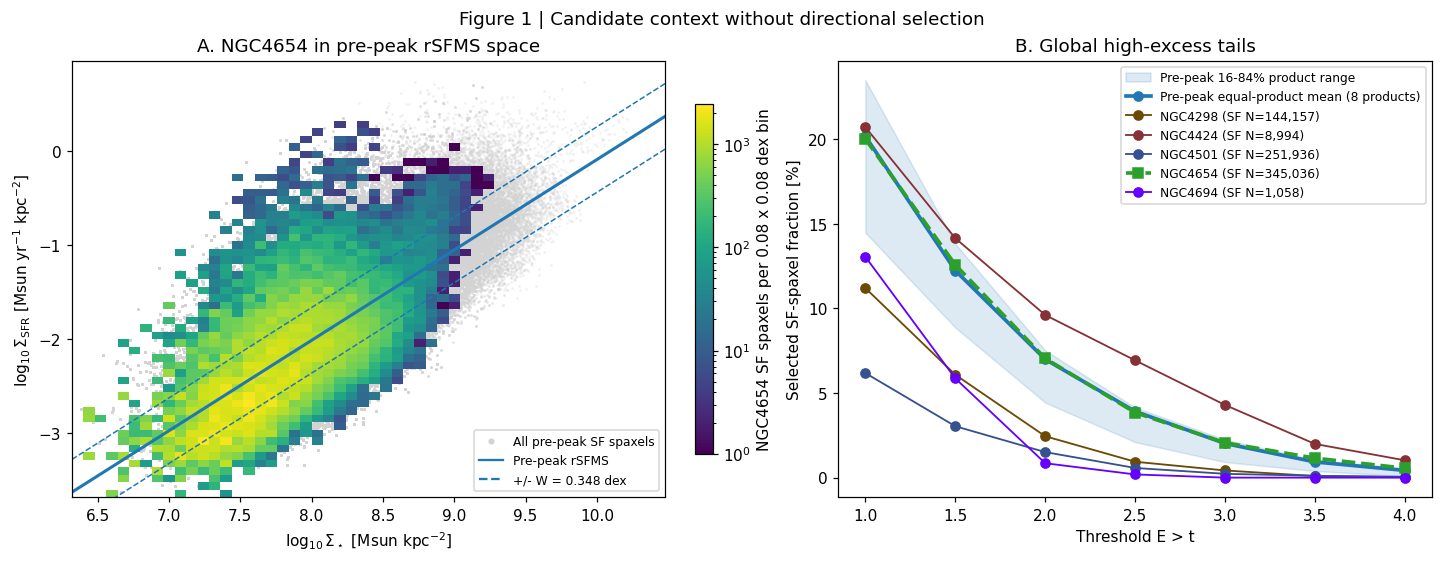

In [20]:
# Figure 1: global candidate context; retain all selected SF pixels.
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The Markdown guide has priority for colours encoding galaxy identity.
paper_colour_guide=PROJECT_ROOT/'20260530_MAUVE_galaxy_colors.md'
paper_galaxy_colours={}
for line in paper_colour_guide.read_text().splitlines():
    if not line.startswith('|'): continue
    fields=[field.strip() for field in line.split('|')[1:-1]]
    if len(fields)==4 and fields[1].startswith(('NGC','IC')):
        colour=fields[3].strip('`')
        if colour.startswith('#'):paper_galaxy_colours[fields[1]]=colour
assert all(g in paper_galaxy_colours for g in close_ids)
# Explicit user overrides for this notebook: full NGC4654 green, mean blue,
# peak dark red, opposite deep blue. Count/excess colormaps encode quantities.
paper_colours={'pre_mean':'#1f77b4','full':'#2ca02c','peak':'#8b0000','opposite':'#00008b'}
paper_thresholds=EXCESS_THRESHOLDS
paper_step=.08
paper_x_values=np.concatenate([pre.x.to_numpy(),target.x.to_numpy()])
paper_y_values=np.concatenate([pre.y.to_numpy(),target.y.to_numpy()])
paper_x_edges=np.arange(np.floor(paper_x_values.min()/paper_step)*paper_step,
    np.ceil(paper_x_values.max()/paper_step)*paper_step+2*paper_step,paper_step)
paper_y_edges=np.arange(np.floor(paper_y_values.min()/paper_step)*paper_step,
    np.ceil(paper_y_values.max()/paper_step)*paper_step+2*paper_step,paper_step)
paper_target_counts=np.histogram2d(target.x,target.y,bins=(paper_x_edges,paper_y_edges))[0]
assert int(paper_target_counts.sum())==len(target)
paper_pre_fractions=fractions.loc[fractions.GALID.isin(pre_ids),
    [f'fraction_excess_gt{t}' for t in paper_thresholds]].to_numpy()
paper_pre_mean=paper_pre_fractions.mean(axis=0)
paper_pre_p16,paper_pre_p84=np.quantile(paper_pre_fractions,[.16,.84],axis=0)

paper_fig1,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
ax=axes[0]
ax.scatter(pre.x,pre.y,s=1,color='lightgray',alpha=.20,rasterized=True,zorder=1)
paper_count_mesh=ax.pcolormesh(paper_x_edges,paper_y_edges,
    np.ma.masked_equal(paper_target_counts.T,0),cmap='viridis',
    norm=LogNorm(vmin=1,vmax=max(2,paper_target_counts.max())),
    shading='flat',rasterized=True,zorder=2)
paper_fig1.colorbar(paper_count_mesh,ax=ax,shrink=.8,
    label='NGC4654 SF spaxels per 0.08 x 0.08 dex bin')
xx=np.linspace(paper_x_edges[0],paper_x_edges[-1],300)
ax.plot(xx,rsfms(xx),color=paper_colours['pre_mean'],lw=2)
ax.plot(xx,rsfms(xx)+width_dex,color=paper_colours['pre_mean'],ls='--',lw=1)
ax.plot(xx,rsfms(xx)-width_dex,color=paper_colours['pre_mean'],ls='--',lw=1)
ax.set(xlim=(paper_x_edges[0],paper_x_edges[-1]),ylim=(paper_y_edges[0],paper_y_edges[-1]),
    xlabel=r'$\log_{10}\Sigma_\star$ [Msun kpc$^{-2}$]',
    ylabel=r'$\log_{10}\Sigma_{\rm SFR}$ [Msun yr$^{-1}$ kpc$^{-2}$]',
    title='A. NGC4654 in pre-peak rSFMS space')
ax.legend(handles=[Line2D([],[],color='lightgray',marker='.',ls='',label='All pre-peak SF spaxels'),
    Line2D([],[],color=paper_colours['pre_mean'],label='Pre-peak rSFMS'),
    Line2D([],[],color=paper_colours['pre_mean'],ls='--',label=f'+/- W = {width_dex:.3f} dex')],
    fontsize=8,loc='lower right')
ax=axes[1]
ax.fill_between(paper_thresholds,100*paper_pre_p16,100*paper_pre_p84,
    color=paper_colours['pre_mean'],alpha=.15,label='Pre-peak 16-84% product range')
ax.plot(paper_thresholds,100*paper_pre_mean,'o-',color=paper_colours['pre_mean'],lw=2.4,
    label=f'Pre-peak equal-product mean ({len(pre_ids)} products)')
for g in close_ids:
    row=fractions.loc[fractions.GALID.eq(g)].iloc[0]
    color=paper_colours['full'] if g==TARGET else paper_galaxy_colours[g]
    ax.plot(paper_thresholds,100*np.array([row[f'fraction_excess_gt{t}'] for t in paper_thresholds]),
        's--' if g==TARGET else 'o-',color=color,lw=2.4 if g==TARGET else 1.2,
        label=f'{g} (SF N={int(row.N_SF):,})')
ax.set(xticks=paper_thresholds,xlabel='Threshold E > t',ylabel='Selected SF-spaxel fraction [%]',
    title='B. Global high-excess tails')
ax.legend(fontsize=8)
paper_fig1.suptitle('Figure 1 | Candidate context without directional selection')
plt.show()

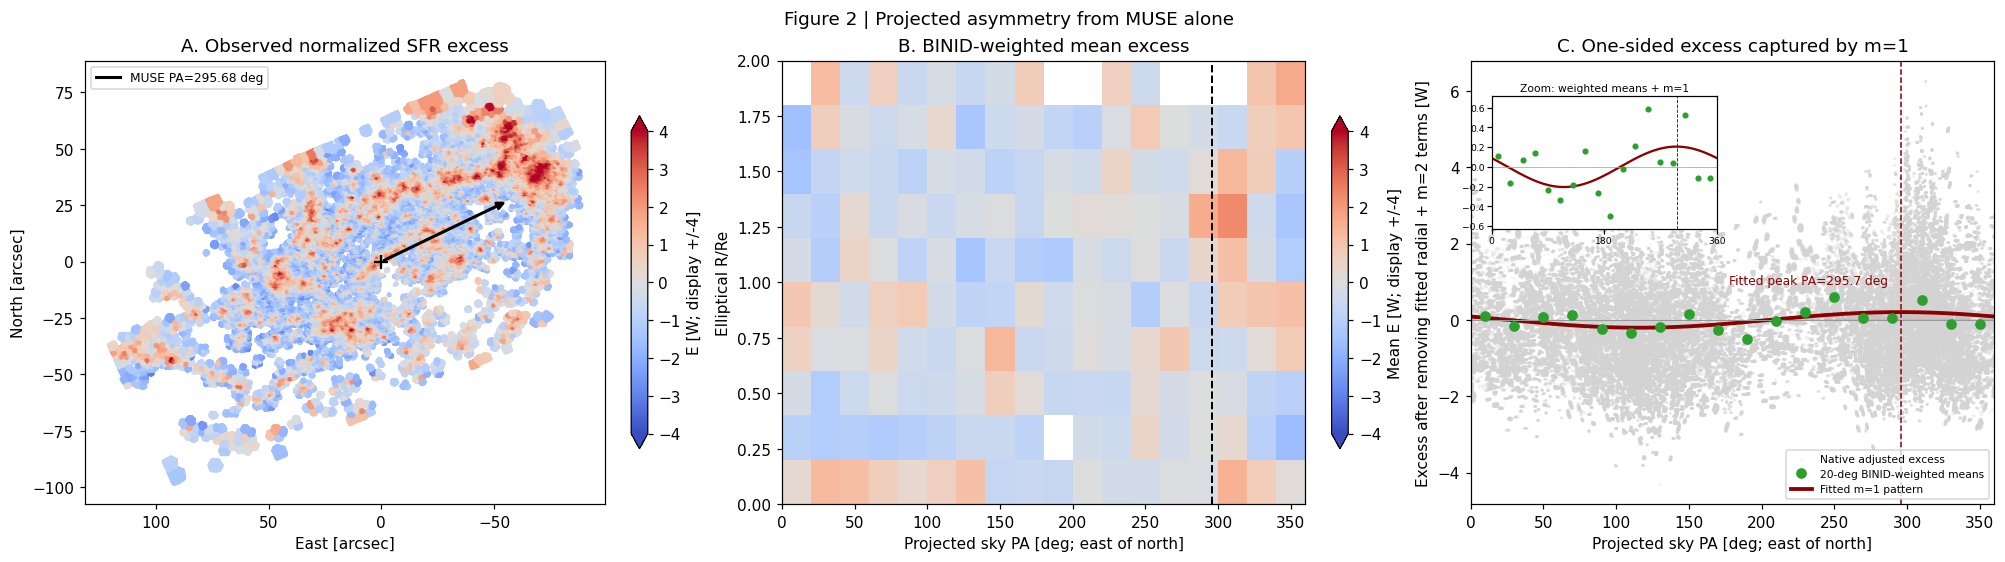

In [21]:
# Figure 2: projected MUSE-only asymmetry; VIVA is absent from every panel.
paper_fit_frame=primary['frame']
paper_fit_weights=primary['weight']
paper_pa=sky_pa(fixed_phase)
paper_theta_edges=np.linspace(0,2*np.pi,19)
paper_theta_centres=np.rad2deg((paper_theta_edges[:-1]+paper_theta_edges[1:])/2)
paper_r_edges=np.arange(int(np.ceil(R_EDGES[max(primary['annuli'])+1]/.2))+1)*.2
paper_sum_weights=np.histogram2d(paper_fit_frame.theta,paper_fit_frame.r,
    bins=(paper_theta_edges,paper_r_edges),weights=paper_fit_weights)[0]
paper_sum_excess=np.histogram2d(paper_fit_frame.theta,paper_fit_frame.r,
    bins=(paper_theta_edges,paper_r_edges),weights=paper_fit_weights*paper_fit_frame.excess.to_numpy())[0]
paper_theta_r_mean=np.divide(paper_sum_excess,paper_sum_weights,
    out=np.full(paper_sum_excess.shape,np.nan),where=paper_sum_weights>0)
np.testing.assert_allclose(paper_sum_weights.sum(),paper_fit_weights.sum())
paper_angular_idx=np.minimum(np.searchsorted(paper_theta_edges,
    paper_fit_frame.theta.to_numpy(),side='right')-1,17)
def paper_weighted_angular_mean(values):
    numerator=np.bincount(paper_angular_idx,weights=paper_fit_weights*np.asarray(values),minlength=18)
    denominator=np.bincount(paper_angular_idx,weights=paper_fit_weights,minlength=18)
    return np.divide(numerator,denominator,out=np.full(18,np.nan),where=denominator>0)
paper_m1_native=primary['amplitude']*np.cos(paper_fit_frame.theta.to_numpy()-fixed_phase)
paper_full_radial_m2=primary['fitted']-paper_m1_native
paper_m1_observed=paper_fit_frame.excess.to_numpy()-paper_full_radial_m2
np.testing.assert_allclose(paper_m1_observed-paper_m1_native,
    paper_fit_frame.excess.to_numpy()-primary['fitted'],atol=1e-12)
paper_arrow_length=.7*min(np.ptp(target.east),np.ptp(target.north))/2
def paper_observed_map(ax):
    m=ax.scatter(target.east,target.north,c=target.excess,s=2,cmap='coolwarm',
        vmin=-4,vmax=4,rasterized=True)
    ax.plot(0,0,'k+',ms=9,mew=1.5)
    ax.set_aspect('equal');ax.invert_xaxis()
    ax.set(xlabel='East [arcsec]',ylabel='North [arcsec]')
    return m
def paper_direction_arrow(ax,pa,color,ls='-',label=None):
    rad=np.deg2rad(pa)
    ax.annotate('',xy=(paper_arrow_length*np.sin(rad),paper_arrow_length*np.cos(rad)),
        xytext=(0,0),arrowprops=dict(arrowstyle='-|>',color=color,lw=2,linestyle=ls))
    if label: ax.plot([],[],color=color,ls=ls,lw=2,label=label)

paper_fig2,axes=plt.subplots(1,3,figsize=(18,5),layout='constrained')
ax=axes[0]
m=paper_observed_map(ax)
paper_direction_arrow(ax,paper_pa,'black',label=f'MUSE PA={paper_pa:.2f} deg')
ax.set_title('A. Observed normalized SFR excess');ax.legend(fontsize=8)
paper_fig2.colorbar(m,ax=ax,shrink=.75,label='E [W; display +/-4]',extend='both')
ax=axes[1]
m=ax.pcolormesh(np.rad2deg(paper_theta_edges),paper_r_edges,
    np.ma.masked_invalid(paper_theta_r_mean.T),cmap='coolwarm',vmin=-4,vmax=4,shading='flat')
ax.axvline(paper_pa,color='black',ls='--',lw=1.3)
ax.set(xlabel='Projected sky PA [deg; east of north]',ylabel='Elliptical R/Re',
    title='B. BINID-weighted mean excess',xlim=(0,360))
paper_fig2.colorbar(m,ax=ax,shrink=.75,label='Mean E [W; display +/-4]',extend='both')
ax=axes[2]
ax.scatter(np.rad2deg(paper_fit_frame.theta),paper_m1_observed,s=1,
    color='lightgray',alpha=.12,rasterized=True,zorder=1,label='Native adjusted excess')
ax.plot(paper_theta_centres,paper_weighted_angular_mean(paper_m1_observed),'o',
    color=paper_colours['full'],ms=6,zorder=3,label='20-deg BINID-weighted means')
grid=np.linspace(0,2*np.pi,361)
paper_m1_curve=primary['amplitude']*np.cos(grid-fixed_phase)
ax.plot(np.rad2deg(grid),paper_m1_curve,color=paper_colours['peak'],lw=2.5,
    label='Fitted m=1 pattern')
ax.fill_between(np.rad2deg(grid),0,paper_m1_curve,where=paper_m1_curve>=0,
    color=paper_colours['peak'],alpha=.08)
ax.axhline(0,color='0.6',lw=.7)
ax.axvline(paper_pa,color=paper_colours['peak'],ls='--',lw=1)
ax.annotate(f'Fitted peak PA={paper_pa:.1f} deg',xy=(paper_pa,primary['amplitude']),
    xytext=(-8,18),textcoords='offset points',ha='right',fontsize=8,
    color=paper_colours['peak'])
ax.set(xlim=(0,360),xlabel='Projected sky PA [deg; east of north]',
    ylabel='Excess after removing fitted radial + m=2 terms [W]',
    title='C. One-sided excess captured by m=1')
# ax.text(.03,.97,'Dots: 20-deg BINID-weighted means',transform=ax.transAxes,va='top',fontsize=8)
ax.legend(fontsize=7,loc='lower right')
# Inset: retain the full PA range, zoom vertically to means and m=1 curve.
paper_zoom_means=paper_weighted_angular_mean(paper_m1_observed)
paper_zoom_values=np.r_[paper_zoom_means[np.isfinite(paper_zoom_means)],paper_m1_curve]
paper_zoom_lo=paper_zoom_values.min();paper_zoom_hi=paper_zoom_values.max()
paper_zoom_pad=.12*max(paper_zoom_hi-paper_zoom_lo,1e-6)
paper_m1_inset=ax.inset_axes([.04,.62,.43,.30])
paper_m1_inset.set_facecolor('white')
paper_m1_inset.plot(paper_theta_centres,paper_zoom_means,'o',
    color=paper_colours['full'],ms=3,zorder=3)
paper_m1_inset.plot(np.rad2deg(grid),paper_m1_curve,color=paper_colours['peak'],lw=1.5)
paper_m1_inset.axhline(0,color='0.65',lw=.5)
paper_m1_inset.axvline(paper_pa,color=paper_colours['peak'],ls='--',lw=.6)
paper_m1_inset.set(xlim=(0,360),ylim=(paper_zoom_lo-paper_zoom_pad,paper_zoom_hi+paper_zoom_pad),
    xticks=[0,180,360])
paper_m1_inset.set_title('Zoom: weighted means + m=1',fontsize=7,pad=3)
paper_m1_inset.tick_params(axis='both',labelsize=6,pad=1)
paper_fig2.suptitle('Figure 2 | Projected asymmetry from MUSE alone')
plt.show()

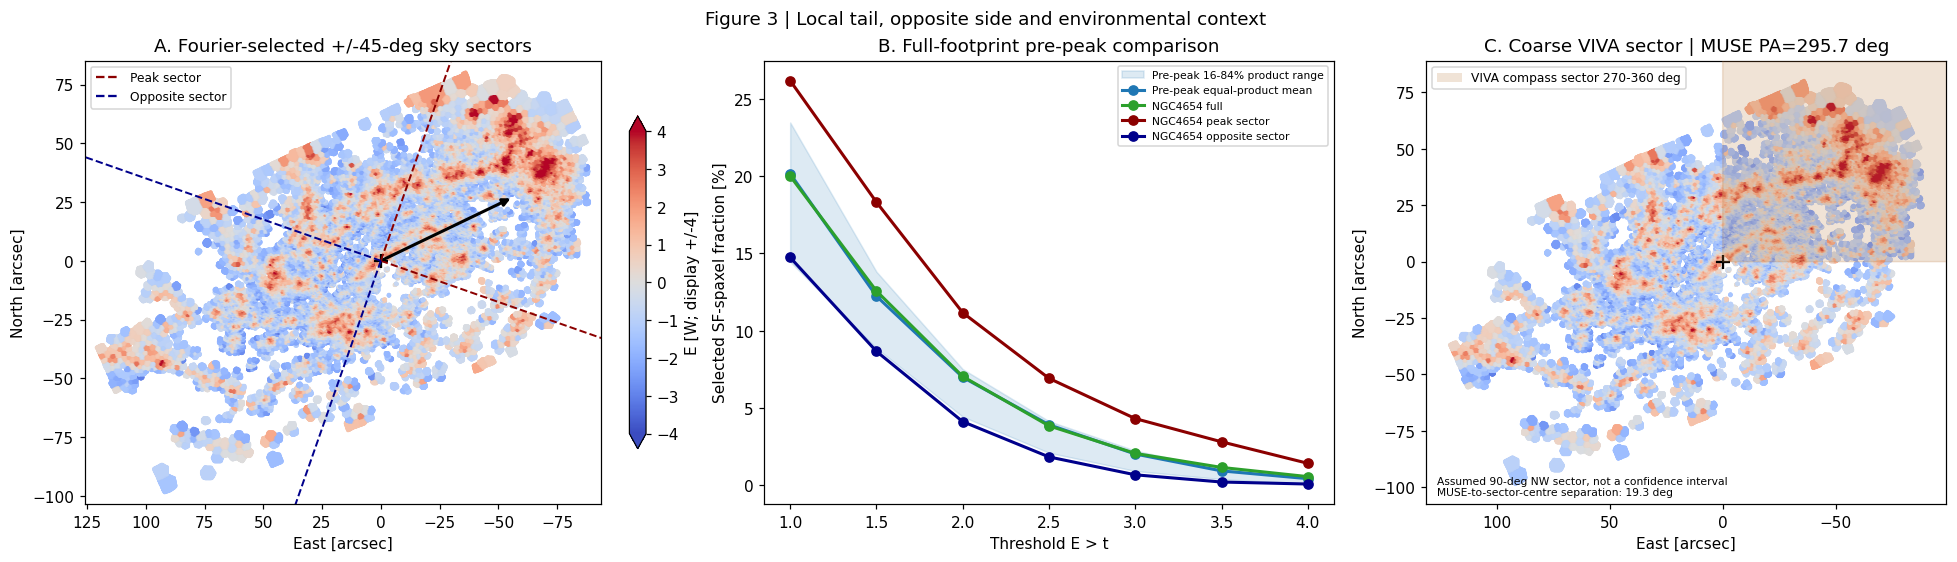

,E>1,E>1.5,E>2,E>2.5,E>3,E>3.5,E>4
Pre-peak equal-product mean,20.159,12.234,6.987,3.914,2.018,0.928,0.425
NGC4654 full,20.003,12.569,7.039,3.842,2.061,1.152,0.557
NGC4654 peak sector,26.178,18.316,11.165,6.917,4.312,2.810,1.419
NGC4654 opposite sector,14.738,8.662,4.115,1.831,0.674,0.208,0.078


PAPER_FIGURES_OK: frozen reference/phase, native maps, full pre-peak reference, descriptive tails


In [22]:
# Figure 3: full-footprint sector tails, then coarse VIVA unblinding.
paper_sector_rows=sector_table.loc[sector_table.selection_scope.eq('Fourier-selected sectors')].set_index('population')
paper_full_row=sector_table.loc[sector_table.selection_scope.eq('Full footprint') & sector_table.population.eq('NGC4654 full')].iloc[0]
paper_tail_vectors={
    'Pre-peak equal-product mean':paper_pre_mean,
    'NGC4654 full':np.array([paper_full_row[f'F_gt{t}'] for t in paper_thresholds]),
    'NGC4654 peak sector':np.array([paper_sector_rows.loc['NGC4654 peak sector',f'F_gt{t}'] for t in paper_thresholds]),
    'NGC4654 opposite sector':np.array([paper_sector_rows.loc['NGC4654 opposite sector',f'F_gt{t}'] for t in paper_thresholds])}
np.testing.assert_allclose(paper_tail_vectors['Pre-peak equal-product mean'],
    [paper_sector_rows.loc['Pre-peak equal-product mean',f'F_gt{t}'] for t in paper_thresholds])
paper_fig3,axes=plt.subplots(1,3,figsize=(18,5),layout='constrained')
ax=axes[0]
m=paper_observed_map(ax)
for centre,color,label in [(paper_pa,paper_colours['peak'],'Peak sector'),
        ((paper_pa+180)%360,paper_colours['opposite'],'Opposite sector')]:
    for edge in [centre-SECTOR_HALF_WIDTH_DEG,centre+SECTOR_HALF_WIDTH_DEG]:
        angle=np.deg2rad(edge)
        length=1.15*max(np.hypot(target.east,target.north))
        ax.plot([0,length*np.sin(angle)],[0,length*np.cos(angle)],color=color,ls='--',lw=1.3)
    ax.plot([],[],color=color,ls='--',label=label)
# Preserve the observed footprint limits after drawing long sector rays.
ax.set_xlim(target.east.max()+5,target.east.min()-5)
ax.set_ylim(target.north.min()-5,target.north.max()+5)
paper_direction_arrow(ax,paper_pa,'black')
ax.set_title(f'A. Fourier-selected +/-{SECTOR_HALF_WIDTH_DEG:g}-deg sky sectors')
ax.legend(fontsize=8)
paper_fig3.colorbar(m,ax=ax,shrink=.75,label='E [W; display +/-4]',extend='both')
ax=axes[1]
ax.fill_between(paper_thresholds,100*paper_pre_p16,100*paper_pre_p84,
    color=paper_colours['pre_mean'],alpha=.15,label='Pre-peak 16-84% product range')
for label,key in [('Pre-peak equal-product mean','pre_mean'),('NGC4654 full','full'),
        ('NGC4654 peak sector','peak'),('NGC4654 opposite sector','opposite')]:
    ax.plot(paper_thresholds,100*paper_tail_vectors[label],'o-',color=paper_colours[key],lw=2,label=label)
ax.set(xticks=paper_thresholds,xlabel='Threshold E > t',ylabel='Selected SF-spaxel fraction [%]',
    title='B. Full-footprint pre-peak comparison')
ax.legend(fontsize=7)
ax=axes[2]
paper_observed_map(ax)
# A coarse NW compass sector, not an H I PA confidence interval.
paper_viva_half_width_deg=45.0
paper_viva_colour='#b87333'
paper_original_xlim=ax.get_xlim();paper_original_ylim=ax.get_ylim()
paper_viva_angles=np.deg2rad(np.linspace(HI_SKY_PA_DEG-paper_viva_half_width_deg,
    HI_SKY_PA_DEG+paper_viva_half_width_deg,100))
paper_viva_radius=1.2*max(np.hypot(target.east,target.north))
paper_viva_x=np.r_[0,paper_viva_radius*np.sin(paper_viva_angles),0]
paper_viva_y=np.r_[0,paper_viva_radius*np.cos(paper_viva_angles),0]
ax.fill(paper_viva_x,paper_viva_y,color=paper_viva_colour,alpha=.20,zorder=3)
ax.set_xlim(paper_original_xlim);ax.set_ylim(paper_original_ylim)
paper_separation=abs((paper_pa-HI_SKY_PA_DEG+180)%360-180)
ax.set_title(f'C. Coarse VIVA sector | MUSE PA={paper_pa:.1f} deg')
ax.legend(handles=[Patch(facecolor=paper_viva_colour,alpha=.20,
    label=f'VIVA compass sector {HI_SKY_PA_DEG-paper_viva_half_width_deg:g}-{HI_SKY_PA_DEG+paper_viva_half_width_deg:g} deg')],fontsize=8)
ax.text(.02,.02,f'Assumed 90-deg NW sector, not a confidence interval\nMUSE-to-sector-centre separation: {paper_separation:.1f} deg',
    transform=ax.transAxes,fontsize=7)
paper_fig3.suptitle('Figure 3 | Local tail, opposite side and environmental context')
plt.show()
paper_tail_summary=pd.DataFrame(paper_tail_vectors,index=[f'E>{t}' for t in paper_thresholds]).T*100
display(paper_tail_summary.round(3))
print('PAPER_FIGURES_OK: frozen reference/phase, native maps, full pre-peak reference, descriptive tails')